# Planes auto-editables: lazo abierto vs. replanificación

**Proyecto final — Inteligencia Artificial: Representación y Solución de Problemas (32310004)**
Universidad del Rosario

> ¿Bajo qué condiciones del entorno un agente que reescribe su propio plan supera a uno con
> plan estático, y a partir de qué costo de reescritura la ventaja se invierte?

Este cuaderno es la lectura de los resultados. El racional está en
[`info/00-rationale.md`](info/00-rationale.md), el diccionario conceptual en
[`info/01-mapping.md`](info/01-mapping.md) y la especificación del experimento en
[`info/02-design.md`](info/02-design.md). El análisis vive en `analysis.py`; aquí solo se
llama y se interpreta. Cabe mencionar que existe una versión simplificada y autocontenida
del mismo modelo (tres políticas, observabilidad total y replanificador exacto) en
[`docs/avance-02/avance-02.ipynb`](docs/avance-02/avance-02.ipynb), que sirve como punto de
entrada más corto antes de este cuaderno.

Las secciones 2 a 8 responden la pregunta con las seis arquitecturas originales. Las
secciones 9 a 15 recogen lo que añadieron después las sesiones del curso sobre modelos
basados en agentes (predador–presa), agentes basados en conocimiento e inferencia
probabilística, es decir, la robustez al orden de activación, la dinámica en el tiempo,
dos arquitecturas nuevas (un agente basado en conocimiento y uno bayesiano), la escasez de
recursos, un análisis de sensibilidad y la calibración por ABC de un despliegue. La §16
junta todo en una explicación de por qué la frontera tiene la forma que tiene, y la §17
cierra con las conclusiones y los límites.

> **Nota sobre una corrección del modelo.** Por transparencia metodológica, cabe mencionar
> que una versión anterior del modelo dejaba que el lazo abierto replanificara gratis tras
> un fallo del plan (con A\* exacto, sin pasar por el oráculo y sin consumir ticks), mientras
> que el lazo cerrado pagaba `c` ticks y la competencia `p` del oráculo en cada reparación,
> de forma que esa asimetría inflaba la ventaja del lazo abierto así como el valor aparente
> de la gobernanza (que, agotado su presupuesto, se comporta como el lazo abierto). La regla
> actual ([`info/02-design.md`](info/02-design.md) §3.2) cobra el mismo replanificador al
> mismo precio a toda política que planifica, el barrido completo se volvió a correr con
> ella, y varias conclusiones de la versión anterior (el dominio del lazo abierto bajo
> observabilidad parcial y el rescate por presupuesto, entre otras) no sobrevivieron a la
> corrección, por lo que las lecturas que siguen se escribieron de nuevo a partir de los
> datos actuales.

## 1. De dónde sale la pregunta

La pregunta no empieza en el curso, sino en un motor de ejecución agéntica propio, OASys, en
el que un agente puede reescribir el programa que lo ejecuta, es decir, puede **monitorear su
plan** (leerlo y compararlo con lo que observa) y **reescribirlo** mientras corre.

Esa capacidad existía pero **nunca se midió**, y tres decisiones de diseño quedaron resueltas
por intuición:

| Decisión | Cómo se resolvía |
|---|---|
| Cuándo surte efecto una edición | **En frío:** la edición aplica en la ejecución siguiente y el trabajo en curso se pierde, mientras que la reparación **en caliente** (la edición aplica sobre la ejecución en curso) no se había construido porque nadie sabía si compensa |
| Cuántas veces deliberar | Un tope fijo de cinco iteraciones, sin justificación derivada |
| Quién autoriza | Reescribir el plan requería autorización humana, de forma que **un humano** era el único freno contra un ciclo de reescrituras improductivas |

Al leer Russell & Norvig con ese motor en mente, resulta que reinventó piezas clásicas: el
plan editable es un **plan jerárquico**, revisarlo contra el mundo es **monitoreo de
ejecución**, reescribirlo es **replanificación**, lo que el agente tiene a la vista es
**observabilidad parcial**, y reiniciar en frío frente a reparar en caliente es exactamente
**lazo abierto frente a lazo cerrado** (R&N §11.5). La tabla completa, concepto por concepto
y con su contraparte en el código, está en [`info/01-mapping.md`](info/01-mapping.md).

Este trabajo modela esa semántica en MESA y mide la frontera.

### Preparación del entorno

El cuaderno no contiene el modelo sino que lo importa: El análisis, la animación, las políticas,
la sensibilidad y la calibración viven como módulos en `project/`, de forma que la celda
siguiente solo pone la raíz del repositorio en `sys.path`, trae los módulos que el resto del
documento usa y define un pequeño ayudante de presentación para las diferencias pareadas. Los
datos ya están en `project/results/` (16.260 corridas en trece barridos, más las series
temporales de `dinamica.parquet` y la tabla de referencia de ABC de `abc.parquet`), por lo que
nada de lo que sigue vuelve a ejecutar un barrido, y las únicas simulaciones que corre el
cuaderno son corridas sueltas (la animación, las tiras de instantáneas, el diagrama de
fiabilidad de la §12 y los despliegues sintéticos de la §15), que en conjunto tardan segundos.

Cabe mencionar que las celdas que dibujan terminan en `;`, lo cual evita que la figura aparezca
dos veces (una como resultado de la celda y otra como figura abierta de matplotlib).

In [1]:
from pathlib import Path
import sys

from IPython.display import display
import pandas as pd

# El paquete es `project`: se importa con la raíz del repositorio en `sys.path`, de modo que
# `project/__init__.py` actúa como el __init__ del paquete y cada módulo resuelve sus propios
# imports (`from project.model import ...`). Los ejemplos vendorizados de Mesa viven aparte,
# en `project/templates/`, y no se importan aquí.
raiz = Path.cwd()
while not (raiz / "project").is_dir() and raiz != raiz.parent:
    raiz = raiz.parent
sys.path.insert(0, str(raiz))

from project import analysis as an  # noqa: E402
from project import animacion as anim  # noqa: E402
from project import calibracion as cal  # noqa: E402
from project import sensibilidad as sens  # noqa: E402
from project.agents import Policy  # noqa: E402

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def contrastes(df, pares, por=("lambda_dinamismo", "radio"), metrica="utilidad_neta"):
    """Diferencias pareadas por semilla, una columna por contraste, como «Δ ± e.e.».

    `pares` es un diccionario {etiqueta: (a, b)}, y cada columna es `a − b` emparejando las
    corridas que comparten semilla y celda (`an.diferencia_pareada`): la varianza entre
    mundos se cancela y el error estándar que se muestra es el de la diferencia.
    """
    columnas = {}
    for etiqueta, (a, b) in pares.items():
        d = an.diferencia_pareada(df, a, b, por=tuple(por), metrica=metrica)
        d = d.set_index(list(por))
        media = d["media"].map("{:+.1f}".format)
        columnas[etiqueta] = media + " ± " + d["err"].map("{:.1f}".format)
    return pd.DataFrame(columnas)


print("políticas:", ", ".join(str(p) for p in Policy))

políticas: REFLEX, MODEL_BASED, OPEN_LOOP, COLD_RESTART, CLOSED_LOOP, GOVERNED, KNOWLEDGE_BASED, BAYESIAN


## 2. El entorno de tarea (PEAS)

| Componente | Especificación |
|---|---|
| **P** — Rendimiento | Recursos entregados en la base antes de `T_max`, penalizado por el tiempo dedicado a deliberar |
| **E** — Entorno | Retícula 15×15 de von Neumann con obstáculos fijos; 8 recursos que se desplazan; base en posición fija |
| **A** — Actuadores | `GOTO`, `PICK`, `DELIVER` y **`DELIBERAR`**, que consume `c` ticks y produce un plan nuevo |
| **S** — Sensores | Contenido de las celdas dentro del radio `r`. Fuera de `r`, solo la creencia |

Clasificación (R&N §2.3.2): **parcialmente observable, estocástico, secuencial, dinámico,
discreto, de un agente**.

La decisión de modelado central es tratar **`DELIBERAR` como un actuador más**: pensar ocupa
ticks del reloj, y el mundo sigue moviéndose mientras el agente piensa. Sin eso no hay costo
que medir y la pregunta se vuelve trivial. De ahí se sigue la segunda decisión: *el plan que
produce una deliberación se calcula con el mundo tal como estaba cuando la deliberación
empezó*. Si el mundo se movió, el plan nace desactualizado.

### Dos términos que carga el resto del documento

**Divergencia.** Se llama divergencia al desacuerdo entre lo que el plan supone del mundo y lo
que el mundo efectivamente hizo: El plan se calculó con un recurso en cierta celda y el recurso
se movió, de forma que la línea `GOTO` que el agente ejecuta apunta a un sitio equivocado. Es el
evento que dispara toda la dinámica, pues sin divergencia no hay nada que replanificar, y de él
se derivan tres métricas: `divergencias_reales` cuenta cuántas veces el plan dejó de ser válido
en el mundo, `divergencias_detectadas` cuántas de ellas el agente llegó a percibir dentro de su
radio y `latencia_deteccion` cuántos ticks pasaron entre lo uno y lo otro. R&N §11.5 distingue
monitoreo de acción, de plan y de objetivo según en qué nivel se detecte ese desacuerdo.

**Utilidad neta.** Es la medida con la que se ordenan todas las políticas y su definición es
`utilidad_neta = valor_entrega × entregas − κ × pasos_deliberando`, con `valor_entrega = 10.0`.
Vale la pena anotarlo con honestidad porque cambia la lectura de cada cifra que sigue: En estos
barridos **κ quedó en 0**, por lo que en la práctica la utilidad neta es exactamente diez veces
las entregas y el único castigo por deliberar es el tiempo que el agente pasa quieto mientras el
mundo se mueve, no un cobro por tokens. Una utilidad de 93.3 significa 9.33 entregas promedio
por corrida.

### Las ocho arquitecturas

| Política | R&N | Cuándo replanifica y cómo aplica la edición |
|---|---|---|
| `REFLEX` | §2.4.2 reflejo simple | — (línea base, sin plan) |
| `MODEL_BASED` | §2.4.3 reflejo basado en modelo | — (sin plan, decide sobre sus creencias y nunca delibera) |
| `OPEN_LOOP` | §2.4.4 basado en objetivos, lazo abierto | Solo cuando el plan falla (no monitorea divergencias), en caliente |
| `COLD_RESTART` | lazo abierto con reinicio | Al detectar una divergencia o al fallar, en frío: en la ejecución siguiente, perdiendo el trabajo en curso |
| `CLOSED_LOOP` | §11.5.3 planeación en línea | Al detectar una divergencia (y al fallar, si aun así ocurre), en caliente: sobre la ejecución en curso |
| `GOVERNED` | lazo cerrado con recursos acotados | Como `CLOSED_LOOP`, con un presupuesto de `B` reparaciones proactivas; agotado, se comporta como `OPEN_LOOP` |
| `KNOWLEDGE_BASED` | cap. 7 basado en conocimiento, con fluentes (§7.7) | Como `CLOSED_LOOP`, pero ante una divergencia solo repara si su base de conocimiento deduce que el plan ya no puede cumplirse al llegar (§11) |
| `BAYESIAN` | §14.2 filtrado y §16.1 utilidad esperada | Como `KNOWLEDGE_BASED`, con una distribución de probabilidad por recurso y λ aprendido; repara solo si reparar cuesta menos, en esperanza, que mantener el plan (§12) |

Las dos últimas se añadieron después, a partir de las sesiones de agentes basados en
conocimiento y de inferencia probabilística, y viven en barridos propios, de forma que los
barridos originales (`principal`, `competencia`, `observabilidad`, `gobernanza` y los controles)
siguen teniendo solo las seis primeras y sus resultados no cambiaron.

**Regla de costo.** Los planes de rutina (el inicial y el que sigue a una entrega sin que
nada haya fallado) son gratuitos, mientras que toda replanificación de reparación, la dispare
un fallo del plan o una divergencia detectada, pasa por el mismo oráculo con competencia `p`
y consume `c` ticks, sea cual sea la política, de forma que las seis políticas que
planifican difieren solo en **cuándo** invocan al replanificador y no en cuánto les cuesta
(el detalle está en [`info/02-design.md`](info/02-design.md) §3.2). El presupuesto `B` acota
solo las reparaciones proactivas (las disparadas por una divergencia), por lo que con `B=0`
`GOVERNED` es idéntica a `OPEN_LOOP` corrida a corrida, lo cual sirve como control exacto
(§3). Lo que `KNOWLEDGE_BASED` y `BAYESIAN` hacen además (actualizar su región o su
distribución y preguntarse si el plan sigue siendo válido antes de pagar `c`) es gratuito
por defecto, igual que observar lo es para todas, y la §11 mide qué pasa cuando cada
consulta se cobra en ticks.

Cabe mencionar que todo plan, sea cual sea la política, termina con una entrega (`DELIVER`)
que queda fuera del **alcance de edición** del agente (es decir, una porción del plan que
ninguna reparación puede modificar), de forma que lo único que distingue a `GOVERNED` de
`CLOSED_LOOP` es el presupuesto `B`.

### Una corrida concreta, tick a tick

Antes de mirar 16.260 corridas agregadas, conviene ver una — y verla **moverse**. Los
agregados de las secciones siguientes dicen *cuánto*; esta animación dice *por qué*.

El reproductor tiene play, pausa y un deslizador: la gracia es parar en el tick exacto en
que el plan se reescribe. Cuatro paneles, que son las cuatro cosas que el modelo tiene:

| Panel | Qué es |
|---|---|
| **El mundo** | La retícula, titulada con el tick, la política y el objetivo actual. Obstáculos en gris, base en verde, agente en azul. Naranja = dónde está **realmente** cada recurso; rombo hueco = dónde **cree** el agente que está. La flecha roja entre ambos es la divergencia, y el anillo morado marca el objetivo del plan |
| **El plan** | El plan como programa, con el contador `▶` en la línea que toca. El `DELIVER` final va marcado como fuera del alcance de edición: ninguna reparación puede tocarlo. Cuando el plan se reescribe, el sufijo nuevo se resalta en verde si la edición se aplicó o en rojo si se rechazó por salirse de ese alcance |
| **Acción del tick** | El espacio de acciones del PEAS. Deliberar es una acción como las otras: ocupa `c` ticks de reloj —la barra— durante los cuales el mundo sigue moviéndose |
| **Métricas** | Lo que se acumula: entregas, ediciones, ediciones desperdiciadas y ticks gastados pensando |

La sombra azul alrededor del agente es su radio de visión `r`: fuera de ahí no se entera
de nada, y eso es exactamente lo que mide la §7.

In [2]:
anim.MODO = "animacion"  # "estatico" para la misma corrida en una sola figura

anim.mostrar(policy="CLOSED_LOOP", lambda_dinamismo=0.5, costo_edicion=2, pasos=80)

**Lectura.** El ciclo completo se ve en los primeros treinta ticks, dado que el agente sale
de la base con un plan de A\*, un recurso se desplaza, el agente detecta la divergencia y pide
una reparación al oráculo, paga `c` ticks quieto (en esta corrida, varias deliberaciones
seguidas se interrumpen porque llega otra divergencia antes de terminarlas), y finalmente el
plan se reescribe desde el contador hacia adelante mientras el `DELIVER` final, que está fuera
del alcance de edición, sobrevive intacto.

Dos cosas conviene mirar con el deslizador:

- **La flecha roja aparece antes que la deliberación:** Ese hueco es la latencia de detección
  de la §7, y mientras dura el agente camina hacia donde el recurso ya no está.
- **Las ediciones desperdiciadas suben en escalón:** Cada salto es una deliberación que se
  pagó y no compró nada, porque otra divergencia llegó antes de terminarla, lo cual es el
  *thrashing* que la §8 intenta acotar con un presupuesto.

Vale la pena volver a correr la celda cambiando `policy="OPEN_LOOP"`, que no monitorea y por
lo tanto descubre el problema solo al intentar recoger (un fallo del plan), aunque luego
replanifica pagando los mismos `c` ticks que el lazo cerrado (con esta misma configuración se
ve una cadena de fallos seguidos, cada uno con su deliberación pagada), así como con
`radio=None`, en cuyo caso la flecha roja casi no aparece porque el agente detecta cada
divergencia en cuanto ocurre, con el pequeño detalle de que eso mismo multiplica las
reparaciones que paga (§7).

**La misma película en una figura.** El reproductor necesita JavaScript, de forma que donde no
corre (el PDF, GitHub o una diapositiva) hace falta un respaldo estático, que es la tira de
instantáneas con la que la sesión de predador–presa cuenta su dinámica en una sola fila. La
celda siguiente corre `CLOSED_LOOP` con un dinamismo alto (λ=0.35, `c=5`, `r=3`, semilla 3) y
dibuja seis ticks equidistantes con el mismo panel del mundo de la animación, enmarcando en
verde los paneles que caen justo después de una edición aplicada.

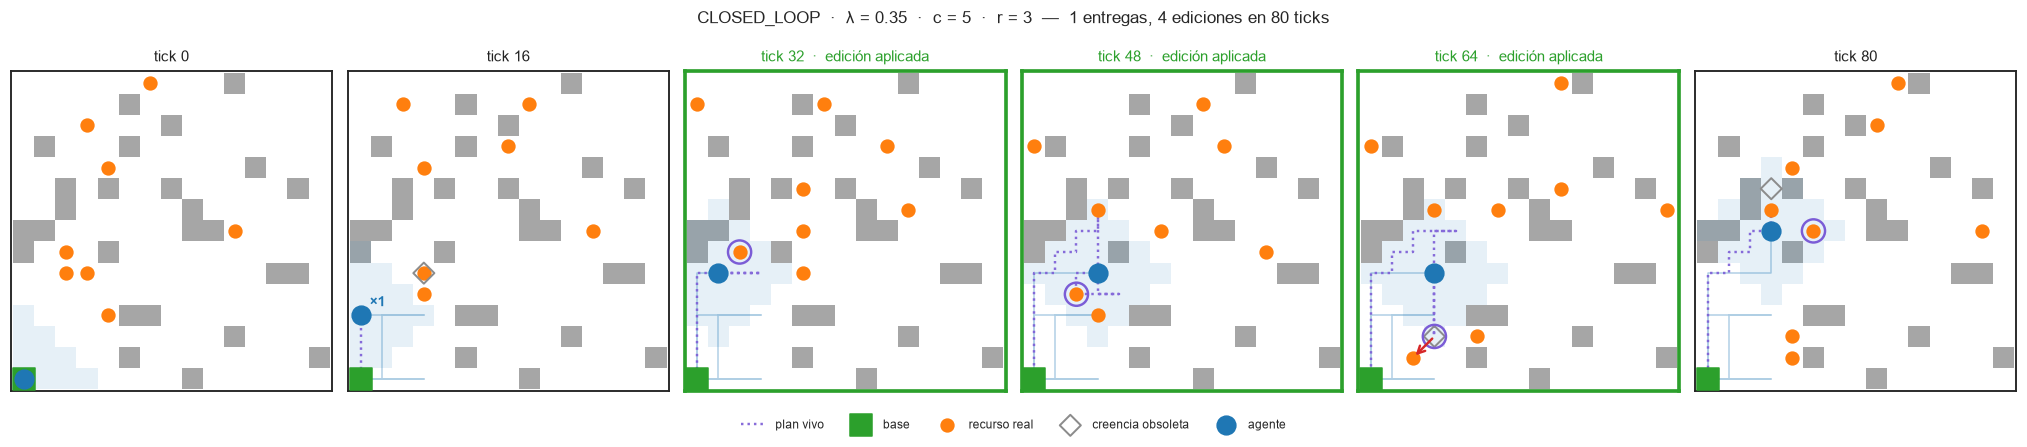

In [3]:
anim.mostrar(
    pasos=80,
    modo="tira",
    policy="CLOSED_LOOP",
    lambda_dinamismo=0.35,
    costo_edicion=5,
    radio=3,
    rng=3,
);

**Lectura.** La tira cuenta en seis paneles lo que la película cuenta en ochenta ticks: En el
tick 16 el rombo hueco de la creencia ya no coincide con el recurso que el plan persigue, los
paneles de los ticks 32, 48 y 64 caen justo después de una reescritura del plan (los marcos
verdes), con el sufijo punteado apuntando cada vez a otro destino, y al final la corrida suma 1 entrega por 4 ediciones aplicadas y 17
desperdiciadas, que es en pequeño la proporción que, agregada sobre 30 réplicas, hunde al lazo
cerrado con λ alto en la §4.

## 3. Controles de sanidad

Ninguna figura vale nada si el modelo no supera antes los controles falsables de
[`info/02-design.md`](info/02-design.md) §9, por lo que se miran primero, y a propósito, dado
que son predicciones hechas *antes* de ver los datos (la numeración es la de esa sección).

- **Control 1 (λ=0 ⇒ `CLOSED_LOOP` = `OPEN_LOOP`):** Sin dinamismo el plan inicial nunca
  caduca, así que replanificar no puede ayudar, y si ayuda hay un error.
- **Control 2 (c=0, p=1, r=∞ ⇒ `CLOSED_LOOP` domina en todo λ):** Si deliberar es gratis, el
  replanificador es perfecto y el agente lo ve todo, más deliberación no puede perjudicar (las
  tres condiciones hacen falta a la vez).
- **Control 3 (p=0.5, c=10, λ bajo ⇒ `CLOSED_LOOP` peor):** Un replanificador mediocre y caro
  destruye un plan correcto, y si no aparece, el modelo de costo no muerde.
- **Control 6 (B=0 ⇒ `GOVERNED` = `OPEN_LOOP`):** Con presupuesto cero `GOVERNED` no puede
  hacer ninguna reparación proactiva y lo único que le queda es replanificar al fallar, con el
  mismo oráculo y al mismo precio que el lazo abierto, por lo que ambas políticas deben
  coincidir corrida a corrida (no solo en promedio), y cualquier diferencia delataría que la
  regla de costo o la gobernanza se aplican distinto a las dos.

Vale la pena anotar con honestidad que no todos pasan con la misma holgura: El control 2 pasa
con margen (la ventaja del lazo cerrado va de +14 a +56 puntos según λ, más de tres errores
estándar de la diferencia pareada en cada λ, y el «Δ mínimo» de la tabla es el de λ=0, donde la
igualdad es exacta), y el 6 pasa sin una sola corrida distinta, mientras que el control 3 pasa
solo por el signo, dado que 85.0 contra 87.5 es una diferencia de 2.5 puntos que queda dentro
del ruido de 30 réplicas (a λ=0.05 la diferencia pareada es −5.0 ± 5.6), por lo que lo prudente
es leerlo como «el lazo cerrado no mejora» más que como «el lazo cerrado empeora».

La columna `estado` de la tabla admite tres valores: `PASA` cuando lo observado cumple la
predicción, `FALLA` cuando la contradice y `NO EVALUABLE` cuando el barrido necesario no se ha
corrido, caso en el que se imprime el comando que lo genera en vez de dar el control por bueno
por ausencia de evidencia. Los controles 4 y 5 de esa misma sección (reproducibilidad bajo la
misma semilla y equivalencia entre A\* y BFS en una retícula sin pesos) no salen en la tabla
porque son propiedades del código y no del barrido, por lo que viven como pruebas en
`project/tests/`. Las dos políticas nuevas traen además sus propios controles exactos (que
se reduzcan a `CLOSED_LOOP` semilla a semilla donde deben hacerlo, y que añadirlas no haya
cambiado ninguna corrida de las políticas viejas), que se muestran en la §11 junto a la
política que controlan.

In [4]:
an.controles()

,control,esperado,observado,estado
0,1. λ=0 ⇒ CLOSED_LOOP = OPEN_LOOP,igualdad exacta,93.3 vs 93.3,PASA
1,"2. c=0, p=1, r=∞ ⇒ CLOSED_LOOP domina en todo λ",CLOSED_LOOP ≥ OPEN_LOOP,Δ mínimo sobre λ = +0.0,PASA
2,"3. p=0.5, c=10, λ bajo ⇒ CLOSED_LOOP peor",CLOSED_LOOP < OPEN_LOOP,85.0 vs 87.5,PASA
3,6. B=0 ⇒ GOVERNED = OPEN_LOOP,igualdad exacta por corrida,"180 pares, 0 distintos; 81.3 vs 81.3",PASA


## 4. La frontera de fase

La figura central: utilidad neta contra dinamismo λ, una línea por política, un panel por
costo de edición `c`. Competencia del oráculo `p=0.9`, radio `r=3`, 30 réplicas por
combinación (3.600 corridas). La banda es el error estándar de la media.

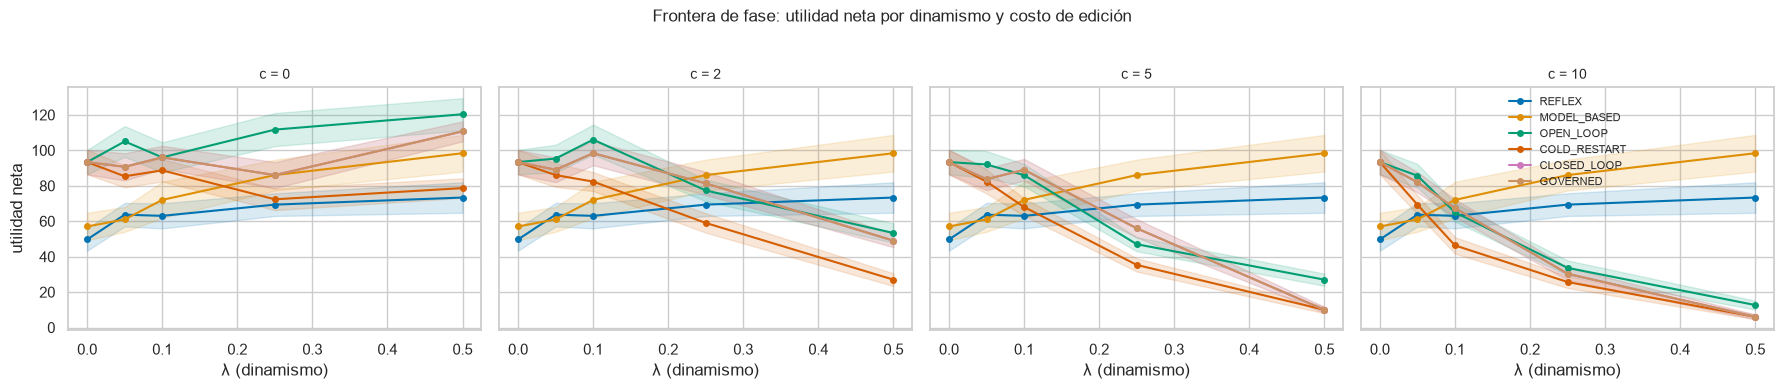

In [5]:
an.fig_frontera();

**Lectura.**

Primeramente, con λ=0 las cuatro políticas que planifican rinden exactamente lo mismo (93.3,
que es el control 1) y casi duplican a las reactivas (49.7 el reflejo simple y 57.0 el basado
en modelo), dado que sin dinamismo el plan nunca caduca y la previsión de A\* para rodear
obstáculos y encadenar objetivos vale más que cualquier reacción.

Progresivamente, a medida que crece λ, la comparación que motivaba el trabajo (reparar al ver
la divergencia, `CLOSED_LOOP`, contra esperar a que el plan falle, `OPEN_LOOP`) resulta mucho
más pareja de lo esperado, de forma que la diferencia `OPEN_LOOP − CLOSED_LOOP` va de −9 a +26
puntos según la celda y en 13 de las 16 celdas con λ>0 cabe dentro de dos errores estándar de
la diferencia pareada (que, con 30 réplicas, está entre 3 y 10 puntos). Las únicas celdas en
que el lazo abierto se adelanta claramente son λ=0.25 con `c=0` (111.7 contra 86.0) y λ=0.5
con `c=5` (27.0 contra 10.0) y `c=10` (12.7 contra 6.0), y estas dos últimas están en un
régimen donde todas las políticas que planifican ya colapsaron, mientras que en ninguna celda
el lazo cerrado se adelanta más allá del ruido, lo cual equivale a decir que, con `r=3` y
cuando ambas cosas cuestan lo mismo, monitorear el plan no compra casi nada sobre replanificar
solo al fallar.

Finalmente, lo que sí aparece con nitidez es otra frontera, la que separa deliberar de no
deliberar en absoluto: El costo de edición `c` hunde a las tres políticas que planifican a
medida que crece, y el hundimiento se acelera con λ, mientras que `MODEL_BASED` (un agente
reactivo que mantiene creencias sobre dónde están los recursos y nunca paga deliberación) no
depende de `c` y mejora con el dinamismo, por lo que pasa a ser la mejor política a λ=0.5 con
cualquier `c≥2` (98.3 contra 53.3, 27.0 y 12.7 de la mejor que planifica con `c=2`, `5` y
`10`) y a λ=0.25 con `c≥5` (86.0 contra 56.0 y 33.7), con márgenes de entre tres y ocho errores
estándar; con `c=2` a λ=0.25 y con `c=10` a λ=0.1 la diferencia cae dentro del ruido. Esa es la
frontera que buscaba la pregunta del trabajo, aunque no entre las dos políticas que se
esperaba, ya que **el costo de reescritura a partir del cual la ventaja se invierte es el costo
a partir del cual deja de convenir planificar, no el que separa al lazo cerrado del lazo
abierto**.

El mecanismo se ve en las métricas de las mismas corridas: A λ=0.5 con `c=5`, `CLOSED_LOOP`
pasa en promedio 282 de los 400 ticks deliberando y entrega 1.0 recurso, mientras que
`OPEN_LOOP`, que replanifica menos veces, pasa 154 ticks deliberando y entrega 2.7, de forma
que ambos gastan buena parte del horizonte pensando sobre un mundo que se mueve mientras
piensan, y cada plan nace desactualizado (§2), en tanto que el agente reactivo reevalúa en cada
tick sin detenerse.

Y un matiz sobre la taxonomía de R&N, que de ahí se sigue: **su orden depende del entorno de
tarea**. `REFLEX` es el peor con λ=0, pero mejora con el dinamismo y a λ=0.5 con `c≥2` supera
también a todo lo que planifica (73.3), de forma que planificar compra previsión y vende
oportunismo, y cuál de las dos vale más es una propiedad del entorno, no del agente.

> `CLOSED_LOOP` y `GOVERNED` se superponen exactamente en esta figura, y debe ser así, dado que
> el barrido principal no fija `presupuesto` y sin presupuesto `GOVERNED` **es** `CLOSED_LOOP`.
> La comparación real entre ambas está en la §8.

> La explicación de *por qué* la frontera tiene esa forma necesita evidencia que se construye
> en las secciones 9 a 15 (la dinámica en el tiempo, el agente basado en conocimiento y la
> escasez, entre otras), por lo que se deja para la §16.

> Cabe mencionar que esta es la lectura que más cambió con la corrección del modelo (nota del
> inicio), pues antes el lazo abierto dominaba en todo λ y todo `c`, con ventajas que llegaban
> a 108 puntos, y esa dominancia era casi entera el efecto de replanificar gratis tras cada
> fallo.

## 5. Cuánto vale reparar en caliente frente a reiniciar en frío

`COLD_RESTART` modela a los sistemas que aplican ediciones en la ejecución siguiente, en los
que la edición solo surte efecto al reiniciar y el trabajo en curso (la carga que el agente
ya llevaba) se pierde, mientras que `CLOSED_LOOP` repara el plan en caliente, es decir, la
edición aplica en sitio sobre la ejecución en curso y el progreso se conserva. La diferencia
entre ambas es el argumento cuantitativo para diseñar motores de ejecución agéntica que
reparen en caliente, o para decidir que no vale la pena.

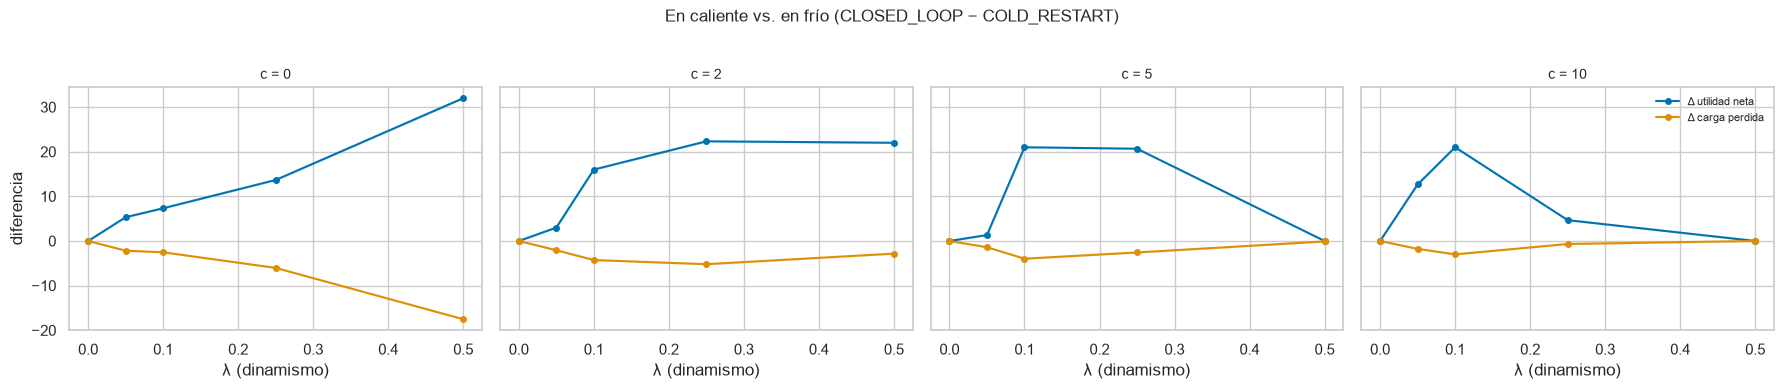

In [6]:
an.fig_hot_vs_cold();

La figura ordena y la tabla cuantifica, filtrada a λ≥0.1 porque es el régimen donde la
diferencia entre aplicar la edición en caliente y reiniciar en frío supera con claridad el
ruido de las 30 réplicas (entre 2.2 y 5.6 errores estándar de la diferencia pareada en todas
las celdas con diferencia no nula). Por debajo, a λ=0.05, las dos políticas casi no se separan
(de +1.3 a +5.3 puntos, dentro del ruido) salvo con `c=10` (+12.7), y el barrido completo,
incluido λ=0 donde la ventaja es exactamente cero, se obtiene quitando el `.query`.

In [7]:
an.delta_hot_vs_cold().query("lambda_dinamismo >= 0.1")

,lambda_dinamismo,costo_edicion,delta_utilidad_neta,delta_carga_perdida,delta_entregas,delta_utilidad_pct
8,0.10,0,7.33,-2.53,0.73,8.27
9,0.10,2,16.00,-4.27,1.60,19.43
10,0.10,5,21.00,-3.97,2.10,30.88
11,0.10,10,21.00,-3.00,2.10,45.32
12,0.25,0,13.67,-6.03,1.37,18.89
13,0.25,2,22.33,-5.20,2.23,37.85
14,0.25,5,20.67,-2.57,2.07,58.49
15,0.25,10,4.67,-0.67,0.47,18.18
16,0.50,0,32.00,-17.53,3.20,40.68
17,0.50,2,22.00,-2.83,2.20,81.48


**Lectura.** La ventaja de reparar en caliente sobre reiniciar en frío es cero en un entorno
estático y aparece con claridad desde λ=0.1, de forma que a λ=0.1 vale entre +7.3 y +21.0
puntos de utilidad según `c` (de +8 % a +45 %), a λ=0.25 entre +4.7 y +22.3, y a λ=0.5 con
deliberación gratuita llega a **+32.0 puntos (+41 %)**, sostenida por la caída de
`carga_perdida` (los recursos que un reinicio en frío suelta) de 17.5 unidades por corrida.
Esta es la conclusión que mejor sobrevive a la corrección del modelo, e incluso se fortalece (a
λ=0.1 con `c=5` la ventaja pasó de +4 a +21 puntos), lo cual tiene sentido, dado que ahora las
dos políticas pagan lo mismo por cada replanificación y lo que las separa es exactamente lo que
la comparación quiere medir, es decir, el trabajo en curso que una conserva y la otra tira.

Vale la pena matizar dos cosas. Primeramente, la relación con `c` no resultó monótona, dado
que a λ=0.25 el máximo está en `c=2` (+22.3) y no en `c=0` (+13.7), y a λ=0.1 la ventaja crece
con `c` en vez de caer, de forma que lo defendible es el signo de la ventaja y su aparición a
partir de λ=0.1, no el valor de cada celda (el porcentaje, además, se infla cuando el reinicio
en frío rinde poco, como el +81 % de λ=0.5 con `c=2`, que son 22 puntos sobre una base de 27).
Finalmente, la ventaja se anula a λ=0.5 con `c≥5`, aunque no porque reiniciar en frío sea bueno
ahí, sino porque las dos políticas colapsan (10.0 contra 10.0 con `c=5`, y 6.0 contra 6.0 con
`c=10`), por lo que no queda trabajo en curso que perder.

Traducido a la decisión de ingeniería: **construir la reparación en caliente compensa en cuanto
el entorno cambia con alguna frecuencia** (desde λ=0.1 en este modelo), siempre que deliberar
no sea tan caro que el agente deje de completar entregas, mientras que en un entorno casi
estático reiniciar en frío no cuesta nada medible y el esfuerzo de construir la reparación en
caliente no tiene retorno.

## 6. ¿Desde qué competencia conviene auto-editarse?

`p` es la probabilidad de que la edición del oráculo sea la reparación óptima. El fallo no es
ruido: es **plausible y equivocado** —objetivo obsoleto, o ruta con desvío— porque es lo que
un LLM comete de verdad.

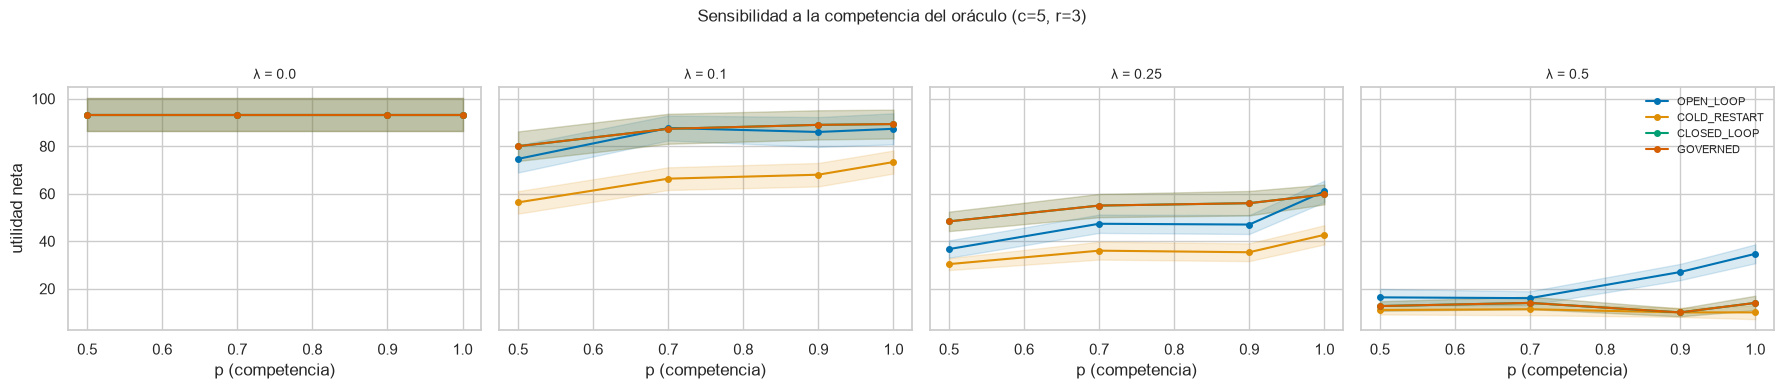

In [8]:
an.fig_competencia();

**Lectura.** La competencia sí mueve el resultado, aunque no del modo que se esperaba, dado
que la política más sensible a `p` resultó ser el lazo abierto y no el lazo cerrado. Entre
`p=0.5` y `p=1.0`, `OPEN_LOOP` pasa de 36.7 a 61.0 a λ=0.25 y de 16.3 a 34.7 a λ=0.5
(pendientes de unos 40 y 37 puntos por unidad de `p`, con un error estándar cercano a 10),
mientras que `CLOSED_LOOP` pasa de 48.3 a 59.7 a λ=0.25 (pendiente de 20 ± 12, apenas por
encima del ruido) y se queda plano a λ=0.5 (entre 10.0 y 14.0), donde lo que lo hunde es la
cantidad de reparaciones que paga y no su calidad; a λ=0.1 todas las pendientes caen dentro del
ruido. Cabe mencionar que en la versión anterior del modelo el lazo abierto no dependía de `p`
en absoluto, porque replanificaba con A\* exacto, de forma que esta pendiente es un efecto
directo de la corrección.

El orden entre ambas cambia entonces con `p`: Con un replanificador mediocre (`p=0.5`) el lazo
cerrado rinde más a λ=0.25 (48.3 contra 36.7, una diferencia pareada de 11.7 ± 4.7), con uno
perfecto empatan (59.7 contra 61.0), y a λ=0.5 el lazo abierto se adelanta solo desde `p=0.9`
(27.0 contra 10.0, y 34.7 contra 14.0 con `p=1`). Una lectura plausible, que no se verificó con
una métrica específica, es que un error del replanificador le cuesta al lazo abierto un viaje
completo hasta la celda equivocada antes de descubrirlo (con el siguiente fallo), mientras que
el lazo cerrado lo corrige en la siguiente observación, aunque pagando otra reparación, por lo
que la calidad de cada reparación pesa más para quien repara poco.

Hay además un límite estructural a lo que `p` puede hacer bajo observabilidad parcial, que
conviene tener presente: Cuando el agente pide una reparación sin poder observar el objetivo
real, el oráculo recibe `true_goal=None` y no hay acierto posible, de modo que construye el
plan hacia la creencia del agente y la propuesta se clasifica como `STALE_TARGET` aunque el
sorteo de competencia haya salido a favor (`oracle.py`, `Oracle.propose`), por lo que con
`r=3` una parte de las consultas no depende de `p`.

Consecuencia para el diseño de motores de ejecución agéntica: Con un replanificador mediocre,
monitorear el plan compensa parte de sus errores, y con uno bueno, invocarlo solo al fallar
basta, de forma que en este barrido no existe una competencia mínima a partir de la cual
reparar al ver la divergencia supere a esperar el fallo (más bien ocurre lo contrario).

## 7. Observabilidad parcial: el radio `r`

El radio de visión `r` modela qué parte del entorno tiene el agente en su contexto (`r=∞`
es observabilidad total). La métrica que importa no es *si* el agente se entera de una
divergencia sino **cuándo**: el plan lo lleva justo a la celda donde creía que estaba el
recurso, así que tarde o temprano lo descubre — mientras tanto camina hacia el sitio
equivocado.

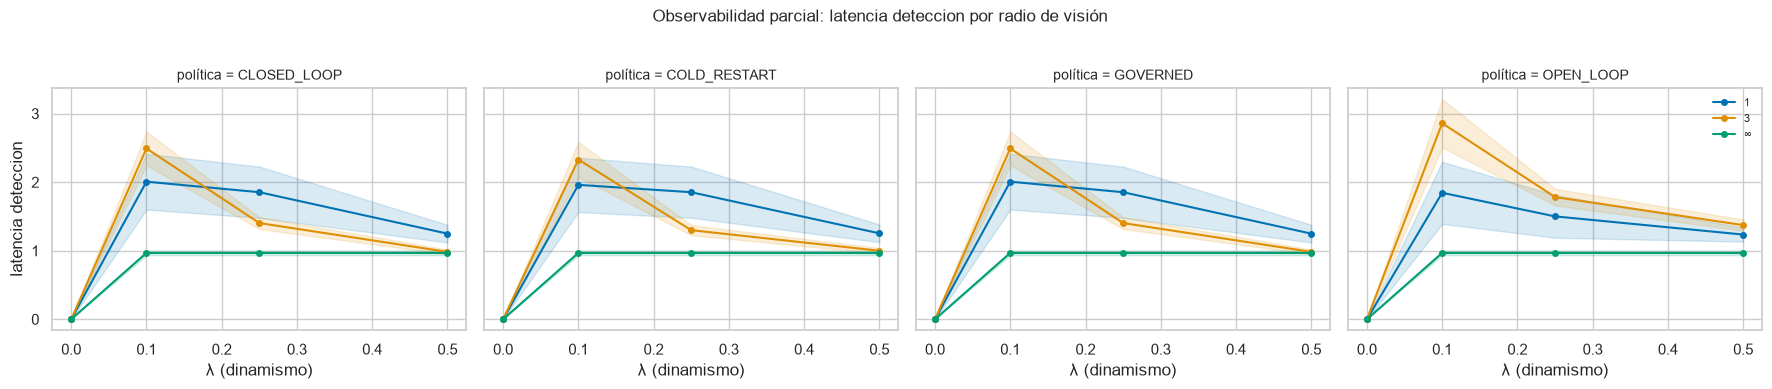

In [9]:
an.fig_observabilidad("latencia_deteccion");

La figura muestra la latencia radio por radio; la tabla siguiente pone juntas las cuatro cifras
que cierran el argumento, promediadas por radio: Latencia de detección, ceguera, número de
ediciones y utilidad neta.

In [10]:
o = an.cargar("observabilidad")
o.groupby("radio")[["latencia_deteccion", "ceguera", "n_ediciones", "utilidad_neta"]].mean().round(2)

,latencia_deteccion,ceguera,n_ediciones,utilidad_neta
radio,,,,
1,1.24,0.03,1.46,48.12
3,1.27,0.02,10.95,59.79
∞,0.72,0.00,14.81,110.23


**Lectura.** La ceguera es casi nula en todos los radios (a lo sumo 3 % en promedio por
radio, y 4.4 % en el peor caso, `OPEN_LOOP` con `r=1`), justo como predecía el diseño, dado que
no se pierden divergencias sino que se detectan tarde: La latencia de detección promedio baja de
1.24–1.27 ticks con `r=1` y `r=3` a 0.72 con `r=∞` (entre `r=1` y `r=3`, cabe mencionar, no hay
un orden claro), y la utilidad media sube de 48.1 con `r=1` a 59.8 con `r=3` y 110.2 con
`r=∞`.

Sin embargo, la tesis de la versión anterior de este cuaderno (que la observabilidad dominaba
todo lo demás y que con visión total la replanificación ganaba) no sobrevive a la corrección
del modelo, por lo que se reescribe a partir de los datos en tres partes:

- **La observabilidad fija el nivel de todas las políticas por igual:** Con λ=0, donde nadie
  replanifica, las cuatro rinden 47.0 con `r=1`, 93.3 con `r=3` y 261.0 con `r=∞`, de forma que
  buena parte del salto de utilidad entre radios es simplemente que ver más permite encontrar
  más recursos, lo cual no dice nada sobre si conviene reescribir el plan.
- **Con `r=1` las cuatro políticas son indistinguibles:** En todo λ quedan a menos de 4 puntos
  entre sí, con un error estándar de ese mismo orden, dado que con tan poca visión el agente
  apenas edita su plan (entre 1.0 y 2.6 ediciones por corrida).
- **Con visión total las diferencias se amplían, pero no a favor de reparar en caliente:** Con
  `c=5` el reinicio en frío colapsa (64.3 a λ=0.1 contra 145.0 del lazo cerrado, y 4.3 contra
  52.0 a λ=0.25), lo cual es la ventaja más grande de reparar en caliente en todo el trabajo,
  pero el lazo abierto supera al lazo cerrado a λ=0.25 (72.0 contra 52.0) y a λ=0.5 (34.0
  contra 0.0), y en promedio sobre λ rinde 129.5 contra 114.5. El mecanismo es que, viéndolo
  todo, el lazo cerrado detecta cada divergencia en cuanto ocurre y paga `c` por cada una, de
  forma que a λ=0.5 pasa 372 de los 400 ticks deliberando y no completa ninguna entrega,
  mientras que el lazo abierto, que solo replanifica al fallar, delibera 171 ticks y entrega
  3.4 recursos.

Es decir que **la observabilidad amplifica lo que el costo de deliberar decide**: Con
deliberación gratuita y oráculo perfecto (el control 2, que también es con `r=∞`) el lazo
cerrado sí domina, por +45 y +56 puntos a λ=0.25 y λ=0.5, mientras que con `c=5` y `p=0.9`
pierde en esos mismos λ. Vale la pena anotar con honestidad que entre esos dos puntos cambian a
la vez `c` y `p`, por lo que la inversión no se puede atribuir solo al costo (aunque la §6
sugiere que `p` pesa poco sobre el lazo cerrado), y que el barrido de observabilidad solo tiene
`c=5`, de modo que la frontera en `c` con visión total queda sin trazar.

## 8. Gobernanza: acotar las ediciones

`GOVERNED` es reparación en caliente con un presupuesto de `B` reparaciones proactivas, de forma
que una vez agotado el presupuesto el agente deja de reparar al ver divergencias y se comporta
exactamente como el lazo abierto (sigue su plan y, si este falla, replanifica pagando `c`, como
toda política). El barrido incluye `B=0`, que es el lazo abierto puro (control 6), de forma que
el eje horizontal va desde no reparar nunca de forma proactiva (`B=0`) hasta reparar sin límite
práctico (`B=25`, que coincide con `CLOSED_LOOP`). `CLOSED_LOOP` no tiene presupuesto, así que
aparece como una recta horizontal de referencia.

Cabe aclarar el alcance de estas dos figuras: Lo que miden es el efecto del presupuesto `B`,
mientras que el **alcance de edición** (la porción del plan que el agente no puede modificar,
aquí la entrega final de todo plan) es común a toda política que replanifica y no distingue a
`GOVERNED` de `CLOSED_LOOP`. El rechazo de una edición que se sale de ese alcance no se
ejercita en el cuaderno sino en las pruebas (`project/tests/`), donde `EditRejected` es la
excepción esperada.

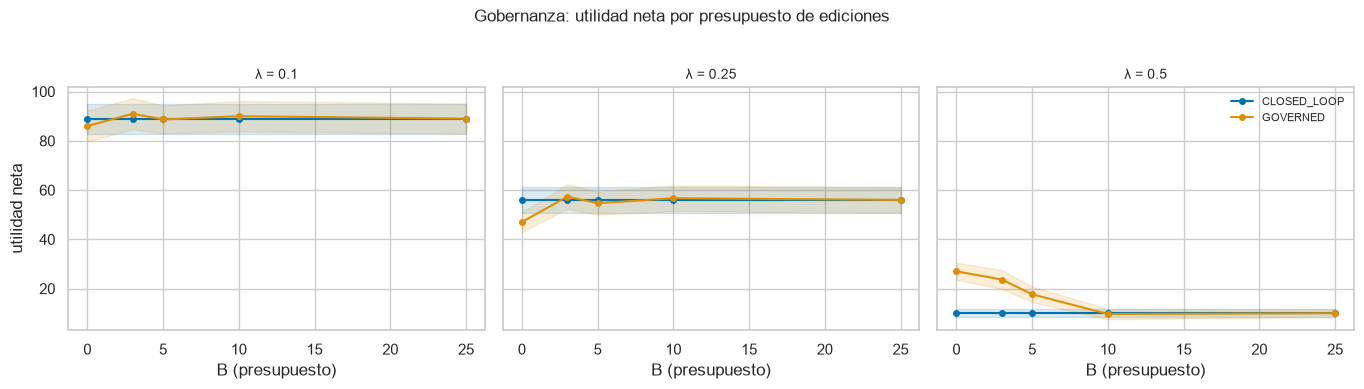

In [11]:
an.fig_gobernanza("utilidad_neta");

Esta segunda figura es la que explica a la primera: Si acotar el presupuesto mejora la
utilidad, debe ser porque recorta las ediciones que no compraron ningún avance.

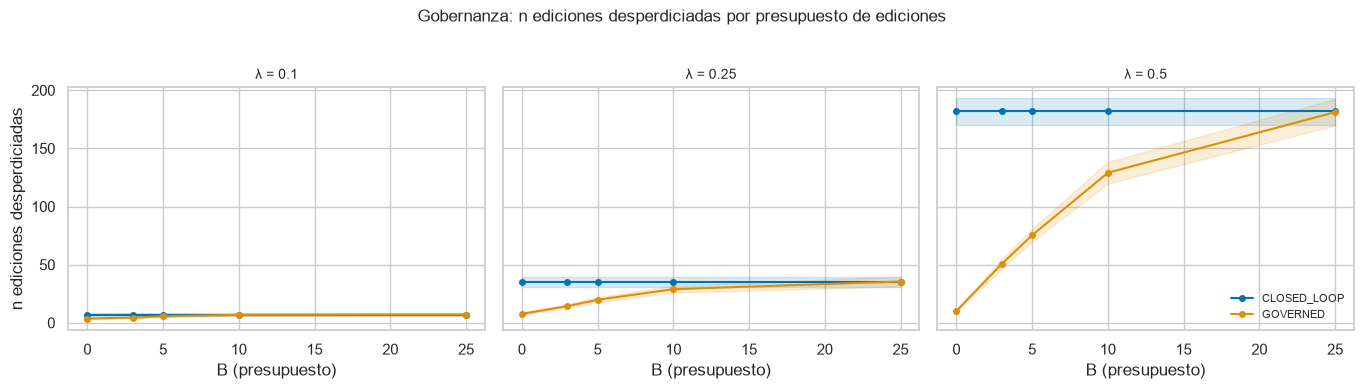

In [12]:
an.fig_gobernanza("n_ediciones_desperdiciadas");

**Lectura.** El presupuesto no rescata al lazo cerrado del modo en que parecía, y la mayor
parte del «rescate» que mostraba la versión anterior de este cuaderno era el mismo artefacto de
la replanificación gratuita, dado que un `GOVERNED` sin presupuesto se comportaba como un lazo
abierto que replanificaba gratis. Con la regla corregida, la lectura por dinamismo es la
siguiente:

- **λ=0.1:** El presupuesto no mueve nada medible, y todas las variantes quedan entre 86.0 y
  91.0, con un error estándar de unos 6 puntos.
- **λ=0.25:** Un presupuesto pequeño recupera el nivel del lazo cerrado sin acotar (57.3 con
  `B=3` contra 56.0), y lo que rinde menos es no reparar nunca de forma proactiva (47.0 con
  `B=0`), aunque esa diferencia de unos 10 puntos apenas supera dos errores estándar.
- **λ=0.5:** Acotar sí ayuda frente al lazo cerrado sin acotar (23.7 con `B=3` contra 10.0),
  pero la utilidad decrece con `B` y el mejor presupuesto es cero (27.0 con `B=0`, que es el
  lazo abierto, aunque su diferencia con `B=3` cae dentro del ruido), de forma que lo que mejora
  el rendimiento no es una cuota óptima sino reparar menos, y todo el régimen queda muy por
  debajo del 98.3 del agente reactivo basado en modelo (§4).

La segunda figura confirma el mecanismo, dado que el *thrashing* es real y el presupuesto lo
corta: A λ=0.5 las ediciones desperdiciadas caen de 181.8 por corrida en el lazo cerrado a 50.7
con `B=3` y a 10.1 con `B=0`, y los ticks deliberando, de 282 a 188 y 154. Cabe mencionar que
acotar las reparaciones proactivas no elimina las replanificaciones, sino que las desplaza hacia
las forzadas por un fallo (de 1.1 por corrida en el lazo cerrado a 22.4 con `B=3` y 30.6 con
`B=0`), que también se pagan. A medida que `B` crece, `GOVERNED` converge a `CLOSED_LOOP`, y con
`B=25` son la misma política.

Vale la pena llevarlo al diseño de motores de ejecución agéntica, donde es habitual acotar la
deliberación con un tope fijo de iteraciones puesto a dedo (cinco, en el caso que motivó la
pregunta): Este barrido no respalda la idea de que un tope bajo sea la razón por la que el
agente funciona, sino una más modesta, en la que acotar las reparaciones proactivas evita el
peor caso cuando el entorno cambia rápido y deliberar es caro, aunque en ese régimen lo que de
verdad funciona es dejar de deliberar, por lo que el tope tendría que derivarse del dinamismo
del entorno y del costo de cada reparación en vez de fijarse.

## 9. Robustez al orden de activación

Hasta aquí, en cada tick el recolector actúa **antes** de que los recursos deriven, de forma que
el agente nunca vive un mundo que se movió en su propio tick, y la sincronización de las
divergencias (y con ella `latencia_deteccion`) depende de ese orden puesto a mano. La sesión de
predador–presa activa a sus agentes en orden aleatorio justamente por eso, ya que quien mueve
primero gana (o pierde) información de forma sistemática, lo cual es una amenaza de validez
interna del experimento y no un error del código. El parámetro `orden_aleatorio=True` sortea en
cada tick, con el generador del modelo (y por lo tanto de forma reproducible), si el recolector
actúa antes o después de la deriva, y el barrido `orden` repite con él un subconjunto de
`principal`: `MODEL_BASED`, `OPEN_LOOP`, `COLD_RESTART` y `CLOSED_LOOP` × λ ∈ {0.1, 0.25, 0.5}
× `c` ∈ {2, 5}, con `r=3` y `p=0.9` (720 corridas).

**Hipótesis (escrita antes de correr).** Si las conclusiones dependen del orden, debería cambiar
el signo de alguna de las tres diferencias que las sostienen: Reparar en caliente frente a
reiniciar en frío (`CLOSED_LOOP − COLD_RESTART`), lazo abierto frente a cerrado
(`OPEN_LOOP − CLOSED_LOOP`) y no planificar frente a la mejor política con plan
(`MODEL_BASED − max`). Lo que se compara es el signo y no el valor, porque sortear el orden cambia
la secuencia de eventos de cada semilla y las corridas dejan de ser pares exactos de las de
`principal`.

In [13]:
an.robustez_orden()

abierto_menos_cerrado                      caliente_menos_frio                      modelo_menos_mejor_plan              \
orden                                           fijo mismo_signo sorteado                fijo mismo_signo sorteado                    fijo mismo_signo   
lambda_dinamismo costo_edicion                                                                                                                           
0.10             2                               7.7        True      8.7                16.0        True      9.3                   -34.0        True   
                 5                              -3.0       False     13.3                21.0        True      9.7                   -17.0        True   
0.25             2                              -4.0       False     12.3                22.3        True     15.3                     4.7       False   
                 5                              -9.0       False      5.3                20.7        True     16.0                    30.0        True   
0.50             2                               4.3        True      3.7                22.0        True     26.7                    45.0        True   
                 5                              17.0        True     14.0                 0.0       False      3.3                    71.3        True   

                                         
orden                          sorteado  
lambda_dinamismo costo_edicion           
0.10             2                -27.7  
                 5                -22.7  
0.25             2                -12.0  
                 5                 16.3  
0.50             2                 33.7  
                 5                 57.7

La tabla anterior compara medias; la siguiente pone el error estándar de las dos primeras
diferencias, emparejando por semilla dentro de cada barrido.

In [14]:
fijo = an.cargar("principal").query(
    "lambda_dinamismo in [0.1, 0.25, 0.5] and costo_edicion in [2, 5]"
)
sorteado = an.cargar("orden")
pares_orden = {
    "caliente − frío": ("CLOSED_LOOP", "COLD_RESTART"),
    "abierto − cerrado": ("OPEN_LOOP", "CLOSED_LOOP"),
}
por_celda = ("lambda_dinamismo", "costo_edicion")
pd.concat(
    {
        "orden fijo": contrastes(fijo, pares_orden, por_celda),
        "orden sorteado": contrastes(sorteado, pares_orden, por_celda),
    },
    axis=1,
)

orden fijo                    orden sorteado                  
                               caliente − frío abierto − cerrado caliente − frío abierto − cerrado
lambda_dinamismo costo_edicion                                                                    
0.10             2                 +16.0 ± 5.6        +7.7 ± 8.2      +9.3 ± 3.3        +8.7 ± 4.6
                 5                 +21.0 ± 5.3        -3.0 ± 5.9      +9.7 ± 3.9       +13.3 ± 5.1
0.25             2                 +22.3 ± 4.1        -4.0 ± 6.7     +15.3 ± 5.0       +12.3 ± 5.1
                 5                 +20.7 ± 5.6        -9.0 ± 5.7     +16.0 ± 3.6        +5.3 ± 6.2
0.50             2                 +22.0 ± 4.1        +4.3 ± 5.3     +26.7 ± 4.4        +3.7 ± 5.0
                 5                  +0.0 ± 0.8       +17.0 ± 3.8      +3.3 ± 1.2       +14.0 ± 5.2

**Lectura.** Las dos conclusiones cualitativas que sostienen el trabajo no dependen de quién
mueve primero, y la tercera diferencia confirma, más que desmiente, lo que ya se sabía de ella:

- **Caliente frente a frío:** El signo coincide en 5 de las 6 celdas, y la sexta no es una
  excepción real, dado que con orden fijo a λ=0.5 y `c=5` las dos políticas colapsan y empatan
  exactamente (0.0 ± 0.8), mientras que con orden sorteado la ventaja del caliente es pequeña
  pero positiva (+3.3 ± 1.2). Con orden sorteado la ventaja es positiva en las seis celdas (de
  +3.3 ± 1.2 en esa celda a +26.7 ± 4.4), aunque más chica que con orden fijo a λ=0.1 (+9.3 y +9.7 contra
  +16.0 y +21.0), lo cual deja la conclusión de la §5 intacta en signo y la vuelve prudente en
  magnitud.
- **No planificar frente a planificar:** El signo coincide en 5 de 6 celdas, y la que cambia
  (λ=0.25 con `c=2`, +4.7 con orden fijo y −12.0 con sorteado) es justamente la que la §4 ya
  había dejado dentro del ruido, mientras que donde la §4 declaraba ganador a `MODEL_BASED`
  (λ=0.5, y λ=0.25 con `c=5`) sigue ganando, con márgenes de +16.3 a +57.7 puntos sobre la mejor
  política con plan.
- **Abierto frente a cerrado:** El signo cambia en 3 de 6 celdas, que es lo que cabe esperar de
  una diferencia que la §4 había encontrado dentro de dos errores estándar en casi todo el
  rango. Vale la pena anotar, eso sí, que con orden sorteado el lazo abierto queda arriba en las
  seis celdas, y en tres de ellas por más de dos errores estándar (+13.3 ± 5.1, +12.3 ± 5.1 y
  +14.0 ± 5.2), de modo que si el orden mueve algo es a favor de no monitorear. En esas corridas
  el lazo cerrado detecta menos divergencias, con más latencia, y delibera menos (a λ=0.1 con
  `c=5`, 34.2 ticks contra 56.2 con orden fijo), aunque el mecanismo que conecta eso con su
  pérdida no se aisló.

En suma, que reparar en caliente supere a reiniciar en frío con λ>0, y que no planificar gane con
λ alto y deliberación cara, son resultados del modelo y no del orden en que se activan sus
agentes, mientras que la comparación entre lazo abierto y lazo cerrado, que ya era la más frágil,
no tiene un signo estable.

## 10. Dinámica: cuándo se separan las políticas

Todas las figuras anteriores muestran el valor **final** de cada corrida contra un parámetro,
porque los barridos guardan solo la última fila de cada corrida, mientras que la figura central de
la sesión de predador–presa es una serie de tiempo, que enseña *cuándo* pasan las cosas y no solo
cuánto. El runner `correr_dinamica` repite la rebanada central de la frontera (`c=5`, `r=3`,
`p=0.9`) con cinco políticas (sin `GOVERNED`, que sin presupuesto es `CLOSED_LOOP`), cuatro
valores de λ y 30 semillas, es decir 600 corridas, guardando una fila cada cinco ticks en
`results/dinamica.parquet`.

**Qué se esperaba.** El plan de este paquete pedía localizar el tick en que el lazo cerrado se
despega del abierto (o del frío) y ver cómo ese punto se mueve con λ, es decir, suponía que las
políticas se separan en un momento identificable, por ejemplo cuando se acumulan las primeras
divergencias. La primera figura muestra las entregas acumuladas, con la banda del error estándar
sobre las 30 semillas.

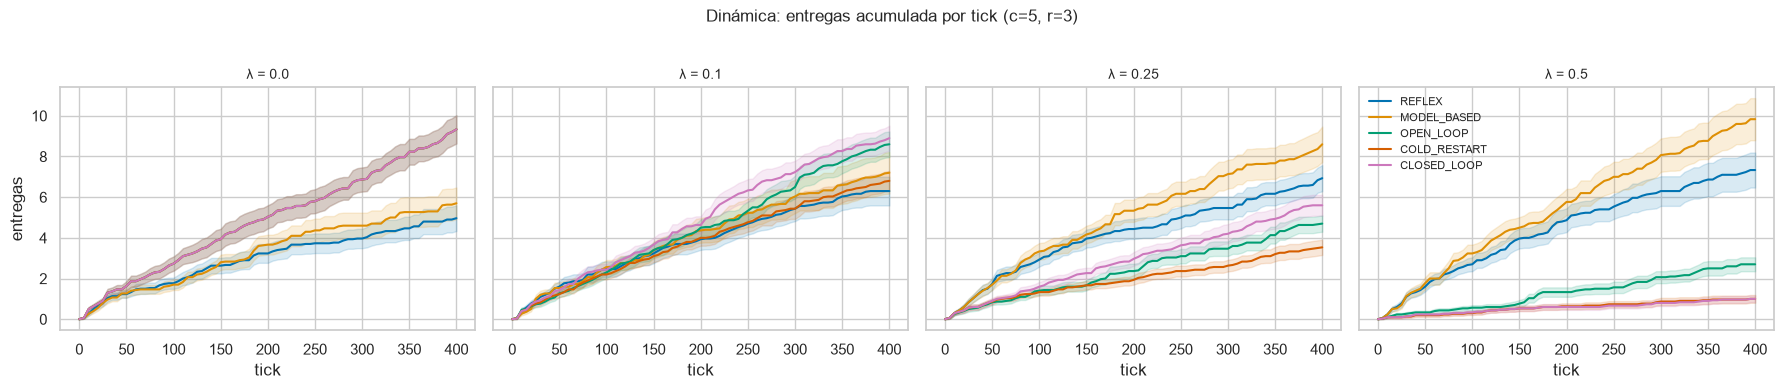

In [15]:
an.fig_dinamica("entregas");

La segunda es la del mecanismo, los ticks gastados deliberando, también acumulados.

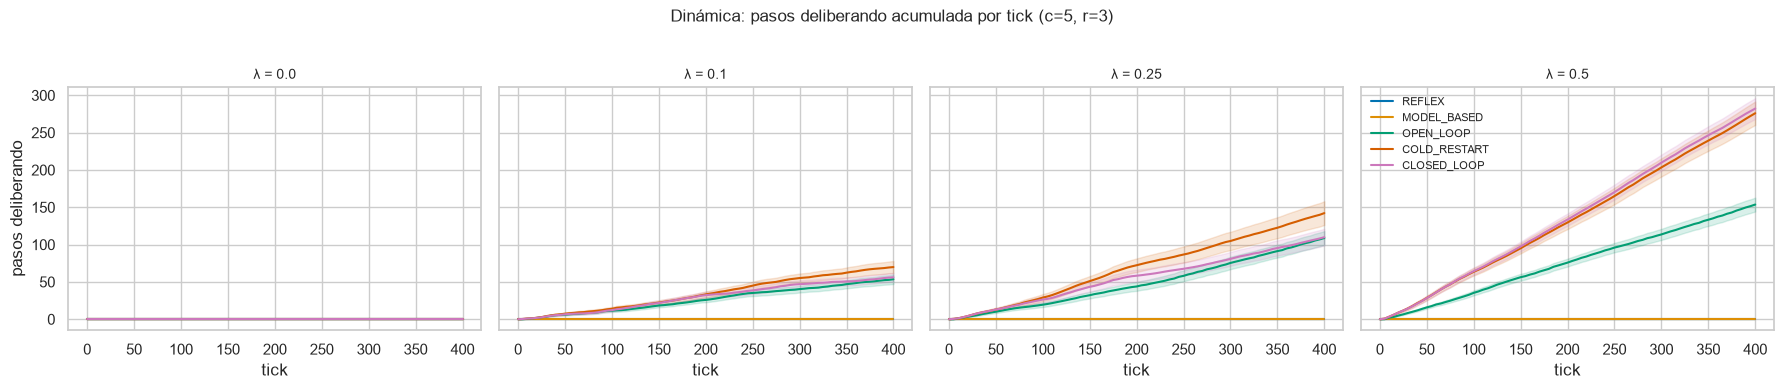

In [16]:
an.fig_dinamica("pasos_deliberando");

Para poner un número al «cuándo», la tabla siguiente busca, para cada par de políticas y cada λ,
el primer tick desde el cual la diferencia pareada de entregas supera dos errores estándar (en
cualquier sentido) y ya no vuelve a bajar hasta el final, y entre paréntesis anota la diferencia
en el tick 400.

In [17]:
din = an.cargar_dinamica()
ancho = din.pivot_table(
    index=["lambda_dinamismo", "rng", "tick"], columns="politica", values="entregas"
)


def separacion(a, b):
    """Por λ: primer tick desde el cual |a − b| supera 2 e.e. hasta el final de la corrida."""
    d = (ancho[a] - ancho[b]).groupby(["lambda_dinamismo", "tick"]).agg(["mean", "sem"])
    d["separadas"] = (d["mean"].abs() / d["sem"]) > 2
    salida = {}
    for lam, g in d.groupby(level="lambda_dinamismo"):
        g = g.droplevel("lambda_dinamismo")
        # True en un tick si desde ahí hasta el final las curvas siempre están separadas.
        hasta_el_final = g["separadas"][::-1].cummin()[::-1]
        final = g.loc[g.index.max()]
        desde = (
            f"tick {hasta_el_final[hasta_el_final].index.min()}"
            if hasta_el_final.any()
            else "nunca"
        )
        salida[lam] = f"{desde} ({final['mean']:+.1f} ± {final['sem']:.1f})"
    return salida


pd.DataFrame(
    {
        f"{a} − {b}": separacion(a, b)
        for a, b in [
            ("MODEL_BASED", "CLOSED_LOOP"),
            ("MODEL_BASED", "OPEN_LOOP"),
            ("CLOSED_LOOP", "COLD_RESTART"),
            ("OPEN_LOOP", "CLOSED_LOOP"),
        ]
    }
).rename_axis("λ")

,MODEL_BASED − CLOSED_LOOP,MODEL_BASED − OPEN_LOOP,CLOSED_LOOP − COLD_RESTART,OPEN_LOOP − CLOSED_LOOP
λ,,,,
0.00,tick 50 (-3.6 ± 1.0),tick 50 (-3.6 ± 1.0),nunca (+0.0 ± 0.0),nunca (+0.0 ± 0.0)
0.10,nunca (-1.7 ± 0.9),nunca (-1.4 ± 1.1),tick 130 (+2.1 ± 0.5),nunca (-0.3 ± 0.6)
0.25,tick 30 (+3.0 ± 1.0),tick 25 (+3.9 ± 0.9),tick 105 (+2.1 ± 0.6),nunca (-0.9 ± 0.6)
0.50,tick 15 (+8.8 ± 1.0),tick 15 (+7.1 ± 1.0),nunca (+0.0 ± 0.1),tick 170 (+1.7 ± 0.4)


**Lectura.** La separación no es un evento sino un ritmo. Primeramente, las curvas de entregas
acumuladas son casi rectas desde el tick 50, de forma que cada política entrega a un paso que
fija λ y lo mantiene (por ejemplo, `CLOSED_LOOP` a λ=0.1 entrega 2.1 recursos por cada 100 ticks
tanto entre los ticks 50 y 200 como entre los ticks 200 y 400, y `OPEN_LOOP` a λ=0.5, 0.7 en
ambos tramos), por lo que las diferencias finales de la §4 son pendientes distintas acumuladas
durante 400 ticks, y no el resultado de un episodio puntual. Progresivamente, la tabla localiza
desde cuándo cada diferencia queda fuera del ruido:

- **Sin dinamismo, el plan vale desde el principio:** Con λ=0 las tres políticas con plan son
  idénticas tick a tick, y `MODEL_BASED` queda por debajo de ellas de forma sostenida desde el
  tick 50 (−3.6 ± 1.0 entregas al final).
- **No planificar se adelanta casi de inmediato cuando el mundo cambia rápido:** `MODEL_BASED`
  supera al lazo cerrado desde el tick 15 con λ=0.5 y desde el tick 30 con λ=0.25 (y al abierto
  desde los ticks 15 y 25), mientras que a λ=0.1 no se separa de ninguno de los dos en toda la
  corrida, lo cual es la frontera de la §4 vista en el tiempo: Con λ alto el agente que planifica
  empieza a perder desde su primera deliberación.
- **Reparar en caliente tarda en pagar:** La ventaja de `CLOSED_LOOP` sobre `COLD_RESTART` se
  separa del ruido recién desde el tick 130 con λ=0.1 y desde el tick 105 con λ=0.25, cuando el
  agente ya acumuló trabajo en curso (carga a bordo, un plan a medio ejecutar) que un reinicio en
  frío tira, y a λ=0.5 no aparece nunca porque ninguna de las dos completa casi entregas (1.0 en
  400 ticks).
- **Abierto frente a cerrado:** Solo se separan a λ=0.5, donde el abierto queda arriba de forma
  sostenida desde el tick 170, y con λ≤0.25 no se separan nunca.

Finalmente, la segunda figura muestra que los ticks deliberando también crecen en línea recta, a
una tasa que fija λ (a λ=0.5, `CLOSED_LOOP` delibera 64 de los primeros 100 ticks y 282 de los
400, es decir, entre el 64 % y el 74 % del tiempo en cada tramo), de modo que el *thrashing* de la
§8 no es una crisis que llegue en algún momento sino un impuesto que se cobra desde el principio
y a ritmo constante. Vale la pena anotar dos límites: El barrido solo tiene `c=5`, por lo que no
dice nada sobre cómo mueve `c` el momento de la separación, y la serie no guarda
`latencia_deteccion`, que sigue leyéndose solo en valores finales (§7).

## 11. Un agente basado en conocimiento: preguntarse antes de pagar

La sesión de agentes basados en conocimiento (R&N cap. 7: el ciclo KB-AGENT con `TELL` y `ASK`,
la lógica proposicional, DPLL, el mundo de Wumpus y el Buscaminas) deja la puerta abierta justo
donde vive este proyecto, pues advierte que en un mundo cambiante habría que indexar los símbolos
por el tiempo (**fluentes**) para que la KB pueda representar cómo cambian las cosas, y su Tarea 4
pregunta qué pasaría con la monotonía si los hoyos se movieran. El modelo es ese mundo
cambiante: Los recursos derivan, las creencias del agente caducan sin que este lo sepa, y la tabla
de creencias de las políticas anteriores solo descarta la creencia **del objetivo actual** cuando
ve vacía su celda, de modo que todo lo que no se ve se trata como verdadero. `KNOWLEDGE_BASED`
hereda la reparación en caliente de `CLOSED_LOOP`, pero sus creencias son una base de
conocimiento, y su inferencia cambia la conducta en el punto exacto donde las demás políticas
pagan, es decir, antes de elegir objetivo y antes de pedir una reparación al oráculo.

### Qué sabe el agente (nivel de conocimiento)

- **Percepción como fluentes:** Cada tick se hace `TELL(Visto(r,c,t))` por cada recurso a la
  vista, `TELL(¬En(r,c,t))` por cada celda a la vista que no lo contiene (`Vacía(c,t)` cuando no
  contiene a ninguno) y `TELL(Recogido(r,t))` al recoger.
- **Monotonía conservada:** Ninguna observación se retira, porque `Visto(r,c,t)` sigue siendo
  verdadera (lo era *entonces*), de forma que lo que caduca es la conclusión «está ahí
  **ahora**», que deja de afirmarse y pasa a **derivarse**.
- **Axioma de deriva:** Como un recurso se mueve a lo sumo a una vecina transitable por tick,
  $En(r,c,t) \Rightarrow \bigvee_{c' \in N^{+}(c)} En(r,c',t{+}1)$, con $N^{+}(c)$ la propia
  celda más sus vecinas transitables, por lo que la distancia que importa es la geodésica y no la
  de Manhattan. Es una ley del mundo que el agente conoce, igual que la regla de la brisa en el
  Wumpus, y con λ=0 se instancia como «los recursos no se mueven», que es todo lo que el agente
  sabe de λ.

### Las tres preguntas `ASK`

1. **¿Dónde puede estar r ahora?** La región posible $R(r,t)$ se fija en $\{c\}$ al ver `r` en
   `c`, se expande un paso por cada deriva mientras no se ve ($R \cup N(R)$) y pierde las celdas
   que se ven sin él, lo cual es la estimación de estado de R&N §4.4 escrita como axiomas de
   estado sucesor (§7.7).
2. **¿Qué recurso tengo asegurado?** El objetivo se elige por el **peor caso**,
   $\max_{x \in R(r,t)} d(\text{agente}, x)$, en vez de por la distancia a la creencia, de modo
   que una creencia vieja, cuya región ya es ancha, pierde frente a una observación reciente un
   poco más lejana, y solo son candidatos los recursos cuya última celda sigue dentro de su
   región.
3. **¿Sigue siendo ejecutable mi plan?** La respuesta tiene tres valores (válido, inválido o
   **desconocido**) y solo *inválido* dispara una reparación. Con el horizonte `"ahora"` el plan
   es inválido si su celda objetivo ya no está en $R(r,t)$, lo cual reproduce exactamente el
   monitor de `CLOSED_LOOP` (el monitor de siempre resulta ser la lectura a nivel de
   implementación de esta consulta); con el horizonte `"llegada"`, si faltan `k` pasos para el
   `PICK`, el plan es inválido solo si el recurso ya no puede estar en esa celda cuando el agente
   llegue, de forma que una deriva pequeña de un objetivo visible deja de costar `c` ticks
   mientras el recurso todavía pueda volver.

Las tres preguntas se resuelven con operaciones de conjuntos sobre la retícula (expansión, resta y
pertenencia), porque codificar $En(r,c,t)$ para cada recurso, celda y tick explotaría en
cláusulas, y la conexión con la lógica del curso se comprueba con pruebas en vez de suponerse
(Newell, 1982, separa justamente el nivel de conocimiento del de implementación): El motor
proposicional de `project/logica.py` (`tt_entails`, CNF, DPLL, una `KnowledgeBase` con respuesta
`desconocido` y la restricción `exactly` del Buscaminas) pasa 20 pruebas, entre ellas el ejemplo
R1–R5 del libro y el acuerdo entre `tt_entails` y `ASK` en 100 oraciones aleatorias; en una
retícula de 4×4 DPLL responde `falso` exactamente fuera de la región y `desconocido` dentro; y en
corridas con λ>0 la celda real de cada recurso cae siempre dentro de su región, que es la versión
honesta del «0 muertes en celda declarada segura» de la sesión. Por último, el parámetro
`ticks_por_ask` (0 por defecto) cobra en ticks quieto cada consulta 2 o 3 hecha ante una
divergencia, y el reporter `n_consultas` las cuenta.

### Hipótesis (escritas antes de correr)

Las hipótesis se fijaron después de la corrección de la regla de costo, con `c=5`, `p=0.9` y 30
semillas, y se evalúan por pares de semilla, es decir, con las dos políticas corriendo sobre el
mismo mundo:

- **H1 (contra el lazo cerrado):** Con $r \in \{1, 3\}$ y λ>0, `KNOWLEDGE_BASED` con horizonte
  `"llegada"` supera a `CLOSED_LOOP`.
- **H1b (contra la mejor política sin reparación proactiva):** Con `r=3`, alcanza en cada λ a la
  mejor de `OPEN_LOOP` y `MODEL_BASED`, con la expectativa, escrita de antemano, de que a λ=0.5
  lo más probable era que fallara (98.3 de `MODEL_BASED` frente a 27.0 del mejor planificador).
- **H2 (control exacto):** Con `r=∞` y horizonte `"ahora"`, la región es un punto en cada
  decisión y la consulta 3 coincide con el monitor actual, por lo que `KNOWLEDGE_BASED` ≡
  `CLOSED_LOOP` semilla a semilla; con λ=0 lo mismo vale en todo radio.
- **H3 (el costo de preguntar):** Con `ticks_por_ask > 0` la ventaja de H1 se encoge y existe un
  valor a partir del cual se invierte, es decir, una frontera análoga a la de `c`.
- **H4 (mecanismo):** Frente a `CLOSED_LOOP`, el horizonte `"llegada"` cambia reparaciones
  proactivas por replanificaciones forzadas por un fallo y reduce los ticks deliberando, y como
  ambas cuestan `c`, H1 solo se sostiene si las reparaciones evitadas superan a los fallos
  añadidos.

Vale la pena anotar que el agente mueve dos palancas a la vez y que conviene leerlas por
separado: El horizonte `"llegada"` ataca el **costo** (evita reparaciones ante derivas pequeñas),
y la elección de objetivo por peor caso ataca la **creencia obsoleta**. Por eso se corre también
la ablación con horizonte `"ahora"` en radios finitos, que no cambia *cuándo* se repara y aísla el
aporte de las preguntas 1 y 2. Los barridos son `conocimiento` (`MODEL_BASED`, `OPEN_LOOP`,
`CLOSED_LOOP`, `KNOWLEDGE_BASED` y `BAYESIAN` × λ × `r` ∈ {1, 3, ∞}, 1.800 corridas),
`conocimiento_ahora` (las dos políticas que infieren con horizonte `"ahora"`, 720) y
`conocimiento_costo` (con 1, 2 y 5 ticks por consulta y `r=3`, 540).

Primero los controles exactos, que se comparan corrida a corrida y no en promedio: H2, su gemela
HB2 de la §12, y la regresión que comprueba que añadir las políticas nuevas no cambió las viejas,
pues las filas de `OPEN_LOOP` y `CLOSED_LOOP` del barrido `conocimiento` deben reproducir
exactamente las de `observabilidad`, y las de `MODEL_BASED` con `r=3`, las de `principal`.

In [18]:
k = an.cargar("conocimiento")
ahora = an.cargar("conocimiento_ahora")
METRICAS = ["entregas", "utilidad_neta", "n_ediciones", "n_ediciones_por_fallo", "pasos_deliberando"]
SIN_POLITICA = ("lambda_dinamismo", "radio", "rng")


def distintas(x, y, claves=("politica", *SIN_POLITICA)):
    """Cuántas corridas de `x` difieren de su par en `y` en alguna métrica."""
    x = x.set_index(list(claves))[METRICAS].sort_index()
    y = y.set_index(list(claves))[METRICAS].sort_index()
    assert x.index.equals(y.index), "los dos lados no tienen las mismas corridas"
    return f"{int((x != y).any(axis=1).sum())} de {len(x)}"


cl = k[k["politica"] == "CLOSED_LOOP"]
obs = an.cargar("observabilidad")
pri = an.cargar("principal")
con_plan = ["OPEN_LOOP", "CLOSED_LOOP"]
pd.Series(
    {
        "H2: KNOWLEDGE_BASED «ahora», r=∞ ≡ CLOSED_LOOP": distintas(
            ahora.query("politica == 'KNOWLEDGE_BASED' and radio == '∞'"),
            cl.query("radio == '∞'"),
            SIN_POLITICA,
        ),
        "HB2: BAYESIAN «ahora», r=∞ ≡ CLOSED_LOOP": distintas(
            ahora.query("politica == 'BAYESIAN' and radio == '∞'"),
            cl.query("radio == '∞'"),
            SIN_POLITICA,
        ),
        "KNOWLEDGE_BASED «llegada», λ=0 ≡ CLOSED_LOOP (todo r)": distintas(
            k.query("politica == 'KNOWLEDGE_BASED' and lambda_dinamismo == 0"),
            cl.query("lambda_dinamismo == 0"),
            SIN_POLITICA,
        ),
        "regresión: OPEN_LOOP y CLOSED_LOOP ≡ observabilidad": distintas(
            k[k["politica"].isin(con_plan)], obs[obs["politica"].isin(con_plan)]
        ),
        "regresión: MODEL_BASED, r=3 ≡ principal (c=5)": distintas(
            k.query("politica == 'MODEL_BASED' and radio == '3'"),
            pri.query(
                "politica == 'MODEL_BASED' and costo_edicion == 5"
                " and lambda_dinamismo in [0.0, 0.1, 0.25, 0.5]"
            ),
        ),
    },
    name="corridas distintas",
).to_frame()

,corridas distintas
"H2: KNOWLEDGE_BASED «ahora», r=∞ ≡ CLOSED_LOOP",0 de 120
"HB2: BAYESIAN «ahora», r=∞ ≡ CLOSED_LOOP",0 de 120
"KNOWLEDGE_BASED «llegada», λ=0 ≡ CLOSED_LOOP (todo r)",0 de 90
regresión: OPEN_LOOP y CLOSED_LOOP ≡ observabilidad,0 de 720
"regresión: MODEL_BASED, r=3 ≡ principal (c=5)",0 de 120


La figura reúne las cinco políticas del barrido `conocimiento`, una faceta por radio (la serie
`BAYESIAN` se discute en la §12).

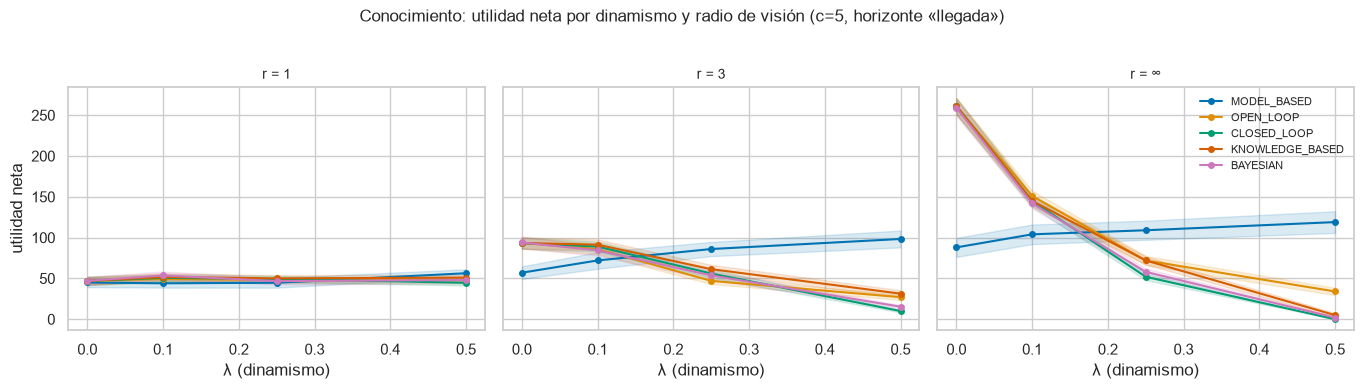

In [19]:
an.fig_conocimiento();

La tabla siguiente pone en números, con `r=3`, los contrastes de H1, de la ablación y de H1b, y
la de después repite H1 y la ablación en los tres radios.

In [20]:
kk = pd.concat([k, ahora.assign(politica=ahora["politica"] + " «ahora»")])
dinamico = kk[kk["lambda_dinamismo"] > 0]
contrastes(
    dinamico[dinamico["radio"] == "3"],
    {
        "H1: KB − CL": ("KNOWLEDGE_BASED", "CLOSED_LOOP"),
        "ablación: KB «ahora» − CL": ("KNOWLEDGE_BASED «ahora»", "CLOSED_LOOP"),
        "H1b: KB − OL": ("KNOWLEDGE_BASED", "OPEN_LOOP"),
        "H1b: KB − MB": ("KNOWLEDGE_BASED", "MODEL_BASED"),
    },
    por=("lambda_dinamismo",),
)

,H1: KB − CL,ablación: KB «ahora» − CL,H1b: KB − OL,H1b: KB − MB
lambda_dinamismo,,,,
0.10,+2.3 ± 6.1,+5.7 ± 4.1,+5.3 ± 4.7,+19.3 ± 10.6
0.25,+5.3 ± 6.2,-3.0 ± 5.1,+14.3 ± 4.2,-24.7 ± 9.8
0.50,+21.3 ± 3.8,-1.3 ± 2.6,+4.3 ± 5.3,-67.0 ± 10.5


In [21]:
contrastes(
    dinamico,
    {
        "KB «llegada» − CL": ("KNOWLEDGE_BASED", "CLOSED_LOOP"),
        "KB «ahora» − CL": ("KNOWLEDGE_BASED «ahora»", "CLOSED_LOOP"),
    },
).unstack("radio")

KB «llegada» − CL                           KB «ahora» − CL                        
radio                            1            3            ∞               1           3           ∞
lambda_dinamismo                                                                                    
0.10                    +1.0 ± 2.1   +2.3 ± 6.1   +0.0 ± 5.6      +0.3 ± 2.0  +5.7 ± 4.1  +0.0 ± 0.0
0.25                    +0.7 ± 2.6   +5.3 ± 6.2  +20.0 ± 5.3      -0.7 ± 2.7  -3.0 ± 5.1  +0.0 ± 0.0
0.50                    +6.3 ± 3.3  +21.3 ± 3.8   +5.0 ± 2.5      -2.7 ± 3.6  -1.3 ± 2.6  +0.0 ± 0.0

H3: la misma diferencia contra el lazo cerrado cuando cada consulta cuesta 0, 1, 2 o 5 ticks
quieto (`r=3`).

In [22]:
costo = an.cargar("conocimiento_costo")
r3 = k[(k["radio"] == "3") & (k["lambda_dinamismo"] > 0)]
kb_costo = costo[costo["politica"] == "KNOWLEDGE_BASED"]
con_costo = pd.concat(
    [r3]
    + [
        kb_costo[kb_costo["ticks_por_ask"] == t].assign(politica=f"KB, {t} tick(s)")
        for t in (1, 2, 5)
    ]
)
contrastes(
    con_costo,
    {
        f"{t} tick(s) por consulta": (
            f"KB, {t} tick(s)" if t else "KNOWLEDGE_BASED",
            "CLOSED_LOOP",
        )
        for t in (0, 1, 2, 5)
    },
    por=("lambda_dinamismo",),
)

,0 tick(s) por consulta,1 tick(s) por consulta,2 tick(s) por consulta,5 tick(s) por consulta
lambda_dinamismo,,,,
0.10,+2.3 ± 6.1,-5.3 ± 5.5,-9.0 ± 4.8,-32.3 ± 5.6
0.25,+5.3 ± 6.2,-17.3 ± 5.6,-30.3 ± 5.8,-36.7 ± 5.6
0.50,+21.3 ± 3.8,-2.3 ± 2.0,-3.7 ± 1.9,-4.7 ± 2.0


H4: el desglose del mecanismo con `r=3` (medias por corrida), donde `proactivas` son las
reparaciones disparadas por una divergencia y `n_ediciones_por_fallo` las replanificaciones
forzadas por un fallo del plan, seguido de la diferencia pareada en ticks deliberando.

In [23]:
mec = r3[r3["politica"].isin(["OPEN_LOOP", "CLOSED_LOOP", "KNOWLEDGE_BASED", "BAYESIAN"])]
mec = mec.assign(proactivas=mec["n_ediciones"] - mec["n_ediciones_por_fallo"])
display(
    mec.groupby(["lambda_dinamismo", "politica"])[
        [
            "n_ediciones_por_fallo",
            "proactivas",
            "n_ediciones_desperdiciadas",
            "pasos_deliberando",
            "n_consultas",
            "entregas",
        ]
    ]
    .mean()
    .round(1)
)
contrastes(
    r3,
    {"Δ pasos deliberando, KB − CL": ("KNOWLEDGE_BASED", "CLOSED_LOOP")},
    por=("lambda_dinamismo",),
    metrica="pasos_deliberando",
)

n_ediciones_por_fallo  proactivas  n_ediciones_desperdiciadas  pasos_deliberando  n_consultas  entregas
lambda_dinamismo politica                                                                                                                
0.10             BAYESIAN                           3.3         6.2                         5.9               56.2         23.1       8.4
                 CLOSED_LOOP                        1.6         7.7                         7.1               56.2          0.0       8.9
                 KNOWLEDGE_BASED                    7.3         2.8                         4.4               53.7         16.0       9.1
                 OPEN_LOOP                         10.6         0.0                         3.6               53.5          0.0       8.6
0.25             BAYESIAN                           7.1        11.9                        38.9              145.6         75.7       5.4
                 CLOSED_LOOP                        1.6         9.7                        35.5              109.9          0.0       5.6
                 KNOWLEDGE_BASED                    9.3         6.5                        24.1              115.5         58.9       6.1
                 OPEN_LOOP                         21.6         0.0                         7.7              108.8          0.0       4.7
0.50             BAYESIAN                           5.7        16.3                       145.8              265.1        208.1       1.5
                 CLOSED_LOOP                        1.1        13.7                       181.8              282.2          0.0       1.0
                 KNOWLEDGE_BASED                    6.6         9.5                        97.4              219.2        192.1       3.1
                 OPEN_LOOP                         30.6         0.0                        10.1              153.6          0.0       2.7

,"Δ pasos deliberando, KB − CL"
lambda_dinamismo,
0.10,-2.5 ± 6.5
0.25,+5.6 ± 13.1
0.50,-63.0 ± 13.6


**Lectura.** Los controles pasan sin una sola corrida distinta, lo cual dice que la región
lógica, con visión total y el horizonte `"ahora"`, es exactamente el monitor de `CLOSED_LOOP`, y
que añadir las dos políticas no tocó a las otras. Los veredictos, en el orden de las hipótesis:

- **H1, a medias:** El signo es el esperado en todas las celdas con $r \in \{1, 3\}$ y λ>0, pero
  la diferencia solo supera el ruido con `r=3` y λ=0.5 (+21.3 ± 3.8, con 31.3 contra 10.0),
  mientras que con `r=1` queda entre +0.7 y +6.3, dentro de dos errores estándar, como era de
  esperar donde las políticas con plan casi no se separan (§7). Fuera del alcance de H1, con
  visión total, `KNOWLEDGE_BASED` también supera al cerrado a λ=0.25 (+20.0 ± 5.3).
- **La ablación dice de dónde sale la ganancia:** Con el horizonte `"ahora"` la ventaja
  desaparece (+5.7 ± 4.1, −3.0 ± 5.1 y −1.3 ± 2.6 con `r=3`), de modo que las preguntas 1 y 2 por
  sí solas, que son las que atacan la creencia obsoleta, no compran nada medible, y todo lo que
  gana `KNOWLEDGE_BASED` viene de la pregunta 3 con horizonte `"llegada"`, es decir, de **no
  pagar reparaciones** ante derivas de las que el recurso todavía puede volver.
- **H1b, se cumple solo con dinamismo bajo:** A λ=0.1 alcanza a la mejor política sin
  reparación proactiva (+5.3 ± 4.7 sobre `OPEN_LOOP`), pero desde λ=0.25 queda por debajo de
  `MODEL_BASED` (−24.7 ± 9.8 y −67.0 ± 10.5), tal como se esperaba para λ=0.5, de forma que saber
  más no compensa frente a no planificar cuando el mundo cambia rápido. Cabe mencionar que a
  λ=0.25 sí supera al lazo abierto (+14.3 ± 4.2), aunque la vara de H1b en esa celda era
  `MODEL_BASED`.
- **H3, se confirma con fuerza:** Basta un tick por consulta para que la ventaja se invierta
  (−5.3 ± 5.5, −17.3 ± 5.6 y −2.3 ± 2.0), y con cinco ticks la pérdida llega a −32.3 ± 5.6 y
  −36.7 ± 5.6 a λ=0.1 y 0.25, mientras que a λ=0.5 es solo −4.7 ± 2.0, porque ahí las políticas
  con plan ya están cerca del colapso. La frontera análoga a la de `c` existe y está muy cerca de
  cero: Razonar solo compensa si es casi gratis frente al costo de deliberar.
- **H4, se confirma:** Con `r=3`, el horizonte `"llegada"` multiplica las replanificaciones
  forzadas por un fallo (7.3, 9.3 y 6.6 por corrida contra 1.6, 1.6 y 1.1 del cerrado) y recorta
  las reparaciones proactivas (2.8, 6.5 y 9.5 contra 7.7, 9.7 y 13.7), y a λ=0.5 delibera
  63.0 ± 13.6 ticks menos y desperdicia 97.4 ediciones contra 181.8, mientras que con λ≤0.25 los
  ticks deliberando no cambian más allá del ruido (y con `r=1` incluso suben un poco). Es decir
  que el intercambio de reparaciones por fallos solo deja ganancia neta donde hay mucho
  *thrashing* que cortar.

Vale la pena anotar un límite que la figura deja a la vista: Con visión total y λ=0.5,
`KNOWLEDGE_BASED` se queda en 5.0 frente a 34.0 del lazo abierto, con 211.5 ediciones
desperdiciadas por corrida (contra 313.6 del cerrado y 10.0 del abierto), de modo que cuando el
agente lo ve todo el horizonte lógico no basta para cortar el *thrashing*.

**La región posible, vista.** La tira siguiente corre `KNOWLEDGE_BASED` en el mismo mundo que la
tira de la §2 (semilla 3, `c=5`, `r=3`) con λ=0.25, y sombrea en naranja la región posible de los
recursos que el agente rastrea, junto al rombo hueco de la última observación de cada uno.

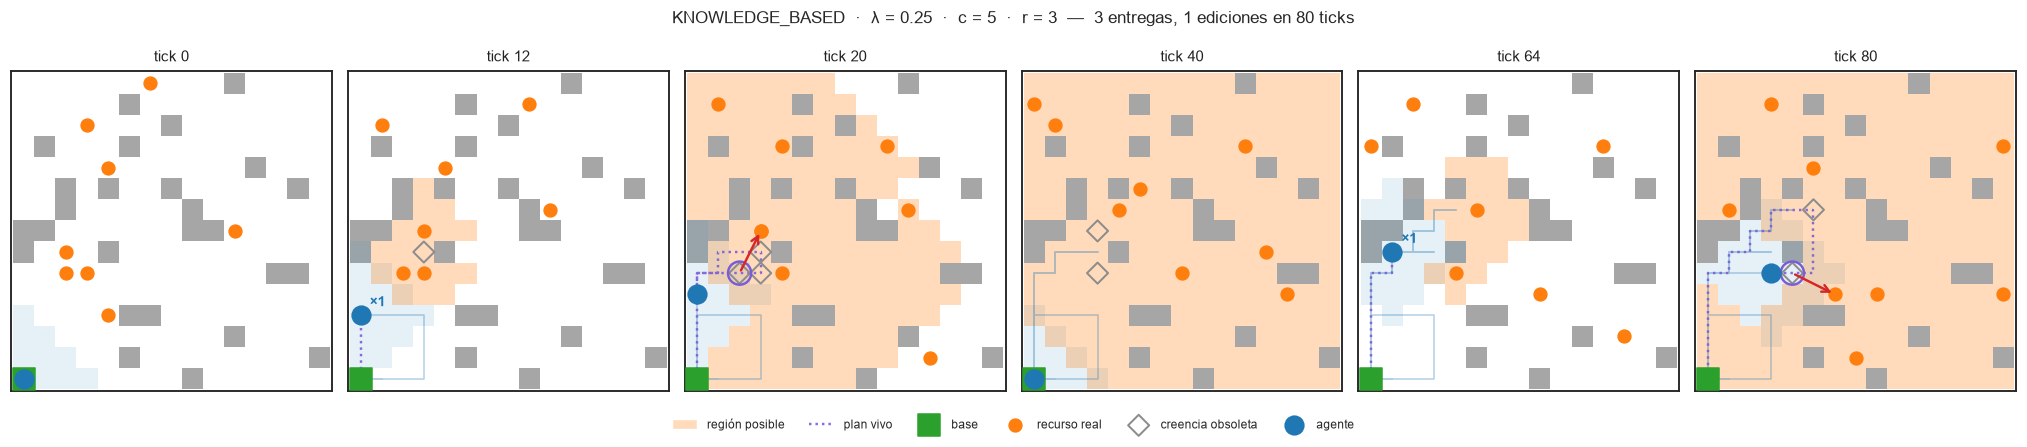

In [24]:
modelo_kb, frames_kb = anim.traza_corrida(
    pasos=80,
    policy="KNOWLEDGE_BASED",
    lambda_dinamismo=0.25,
    costo_edicion=5,
    radio=3,
    rng=3,
)
anim.figura_tira(frames_kb, modelo_kb, pasos=[0, 12, 20, 40, 64, 80]);

**Lectura.** La región se comporta como dicen los axiomas: En el tick 12 es una mancha pequeña
alrededor de la última celda vista, en los ticks 20 y 40 ya cubre buena parte del mapa (con
λ=0.25, una observación de hace veinte ticks apenas descarta nada), y en el tick 64 se encoge de
nuevo, porque el disco de visión resta las celdas que ve vacías y colapsa a un punto la región de
cada recurso que vuelve a ver. La flecha roja del tick 20 es una divergencia que el agente detecta
y **no** repara, porque el recurso todavía puede estar en su celda cuando llegue, y en toda la
corrida delibera 8 ticks, contra 25 de `CLOSED_LOOP` en el mismo mundo y con el mismo λ (con 3
entregas contra 4, lo cual, en una sola corrida, no dice nada sobre cuál rinde más).

### Respuesta a la Tarea 4 y límite honesto

La Tarea 4 de la sesión preguntaba qué pasa con la monotonía si los hoyos se mueven, y la
respuesta que da este agente es empírica: **La monotonía no se rompe, se indexa por el tiempo.**
Ninguna oración se retira nunca (`Visto(r,c,t)` sigue siendo verdadera), lo que caduca es la
conclusión «está ahí ahora», que pasa de afirmarse a derivarse con el axioma de deriva, y la
prueba de solidez dice que esa derivación nunca deja fuera la celda real. La tabla de creencias
de las otras políticas, en cambio, borra y sobrescribe sin dejar rastro, y por eso no puede saber
cuán vieja es una creencia.

El límite, que también es el de la sesión, es que la lógica dice dónde **puede** estar un recurso
y no dónde **probablemente** está: El peor caso trata igual una celda en el centro de la región
que una en su borde, y el horizonte `"llegada"` mantiene planes posibles pero improbables. Es el
mismo límite del dilema de la semilla 6 en el Wumpus de la sesión, donde la KB responde
`desconocido` para todas las candidatas aunque una explique ambas brisas en 4 de 5 modelos, y que
la sesión deja para la Tarea 5 (contar modelos). Cruzarlo es exactamente lo que intenta la
sección siguiente.

## 12. Un agente bayesiano: saber cuánto se sabe

La sesión de inferencia probabilística para modelos basados en agentes trae las piezas que faltan
para cruzar el límite de la §11, y lo dice ella misma en su versión probabilística del Wumpus:
Cuando la lógica no decide, la probabilidad elige la celda menos riesgosa. `BAYESIAN` sabe lo
mismo que `KNOWLEDGE_BASED` (la ley de deriva, lo que ve y lo que ve vacío), con dos diferencias,
ya que no recibe λ sino que lo aprende, y en vez de una región mantiene una distribución de
probabilidad por recurso.

### Qué sabe el agente

- **λ aprendido (Beta–Bernoulli):** Con prior Beta(1,1), cada recurso cuya celda anterior sigue
  a la vista es un ensayo de Bernoulli (se movió o no), de modo que $\hat\lambda$ es la media
  posterior y su incertidumbre decrece como $1/\sqrt{n}$. Cabe mencionar una desviación respecto
  del diseño original, que exigía ver el recurso en los dos ticks: Esa regla sesgaba
  $\hat\lambda$ hacia abajo (0.38 con λ=0.5 y `r=1`), porque un recurso que sale del disco de
  visión es un movimiento que no se ve.
- **Un filtro *forward* por recurso (R&N §14.2):** Al ver el recurso la distribución colapsa a
  su celda, y en cada tick sin verlo se predice con la caminata aleatoria,
  $P'(x) = (1-\hat\lambda)P(x)[\deg x>0] + P(x)[\deg x = 0] + \hat\lambda\sum_{y\sim x} P(y)/\deg y$,
  y se corrige poniendo a cero las celdas vistas sin el recurso y renormalizando. El soporte de
  esa distribución es exactamente la región posible de la §11, lo cual se comprueba tick a tick
  en las pruebas, de forma que el filtro no sabe *dónde puede estar* nada distinto de lo que sabe
  la lógica, sino que le asigna pesos.

### Las dos decisiones

1. **Objetivo por costo esperado:** Se elige el recurso que minimiza $d/q$, con $d$ la distancia
   a su última celda observada y $q$ la probabilidad de que siga ahí al llegar (el filtro
   propagado $d$ pasos), entre los mismos candidatos que admite la §11.
2. **Reparar o mantener por utilidad esperada (R&N §16.1):** Ante una divergencia, con `k` pasos
   hasta el `PICK` y $q$ la probabilidad de que el recurso esté en esa celda al llegar, se repara
   si y solo si $c < (1-q)(c+k)$, es decir, si pagar `c` ya cuesta menos que la esperanza de
   caminar `k` pasos en vano y pagar después la replanificación forzada. Con `c=5` y `k=3`, por
   ejemplo, la regla repara cuando $q < 3/8$, mientras que `KNOWLEDGE_BASED` solo repara cuando
   $q = 0$.

Con el horizonte `"ahora"` ambas decisiones se evalúan en el tick actual ($q$ sin propagar), y con
visión total eso reduce `BAYESIAN` a `CLOSED_LOOP`, que es el control HB2 de la tabla de la §11.

### Hipótesis (escritas antes de correr)

- **HB1:** Con $r \in \{1, 3\}$ y λ>0, `BAYESIAN` supera a `KNOWLEDGE_BASED` (ambos con
  `"llegada"`), porque el peor caso descarta por igual objetivos casi seguros y casi perdidos, y
  el horizonte lógico mantiene planes posibles pero improbables.
- **HB2 (control exacto):** Con `r=∞` y `"ahora"`, `BAYESIAN` ≡ `CLOSED_LOOP` semilla a semilla.
- **HB3:** $|\hat\lambda-\lambda|$ al final de la corrida es pequeño y decrece con el número de
  ensayos, por lo que con `r=1` el agente decide con un λ peor estimado.
- **HB4:** A λ=0.5 y `c=5`, `BAYESIAN` sigue por debajo de `MODEL_BASED`, porque el criterio
  evita reparaciones proactivas pero no las forzadas por un fallo, de modo que el paquete mide
  cuánto de la brecha con no planificar cierra saber cuánto se sabe.
- **HB5 (calibración):** Con λ conocido, las celdas a las que el filtro asigna probabilidad
  $\approx x$ contienen al recurso con frecuencia $\approx x$.

Los datos son los mismos barridos de la §11, en los que `BAYESIAN` corre junto a las demás.

In [25]:
contrastes(
    dinamico,
    {
        "HB1: BAYES − KB": ("BAYESIAN", "KNOWLEDGE_BASED"),
        "BAYES − CL": ("BAYESIAN", "CLOSED_LOOP"),
        "HB4: BAYES − MB": ("BAYESIAN", "MODEL_BASED"),
        "BAYES «ahora» − BAYES": ("BAYESIAN «ahora»", "BAYESIAN"),
    },
)

HB1: BAYES − KB  BAYES − CL HB4: BAYES − MB BAYES «ahora» − BAYES
lambda_dinamismo radio                                                                  
0.10             1          +2.0 ± 2.6  +3.0 ± 2.0      +9.7 ± 4.6            -5.0 ± 3.1
                 3          -7.0 ± 6.9  -4.7 ± 5.7     +12.3 ± 9.6            +9.3 ± 6.6
                 ∞          -3.0 ± 5.3  -3.0 ± 4.8    +38.0 ± 11.9            +3.0 ± 4.8
0.25             1          -3.3 ± 2.4  -2.7 ± 3.1      +2.0 ± 5.5            +2.0 ± 2.6
                 3          -7.7 ± 6.1  -2.3 ± 6.0     -32.3 ± 9.1            -1.0 ± 5.4
                 ∞         -14.0 ± 5.5  +6.0 ± 4.9    -51.0 ± 11.7            -6.0 ± 4.9
0.50             1          -3.0 ± 4.5  +3.3 ± 4.2      -8.3 ± 5.5            -6.0 ± 4.8
                 3         -16.0 ± 4.3  +5.3 ± 2.4    -83.0 ± 10.3            -6.0 ± 2.6
                 ∞          -3.0 ± 2.6  +2.0 ± 1.4   -117.0 ± 13.8            -2.0 ± 1.4

HB3: la mediana del error final $|\hat\lambda - \lambda|$, por radio y por λ.

In [26]:
bayes = k[k["politica"] == "BAYESIAN"]
bayes = bayes.assign(error=(bayes["lambda_estimado"] - bayes["lambda_dinamismo"]).abs())
error_lambda = bayes.pivot_table(
    index="radio", columns="lambda_dinamismo", values="error", aggfunc="median"
)
error_lambda["todas"] = bayes.groupby("radio")["error"].median()
error_lambda.round(3)

lambda_dinamismo,0.0,0.1,0.25,0.5,todas
radio,,,,,
1,0.134,0.051,0.083,0.080,0.083
3,0.020,0.021,0.020,0.018,0.020
∞,0.000,0.003,0.005,0.005,0.003


HB5: el diagrama de fiabilidad corre seis corridas cortas (λ=0.25, `r=3`, 300 ticks) en las que
un filtro de prueba con λ conocido incorpora las mismas observaciones que el agente, y anota, para
cada celda fuera de la vista con probabilidad positiva, la probabilidad asignada y si el recurso
estaba de verdad ahí.

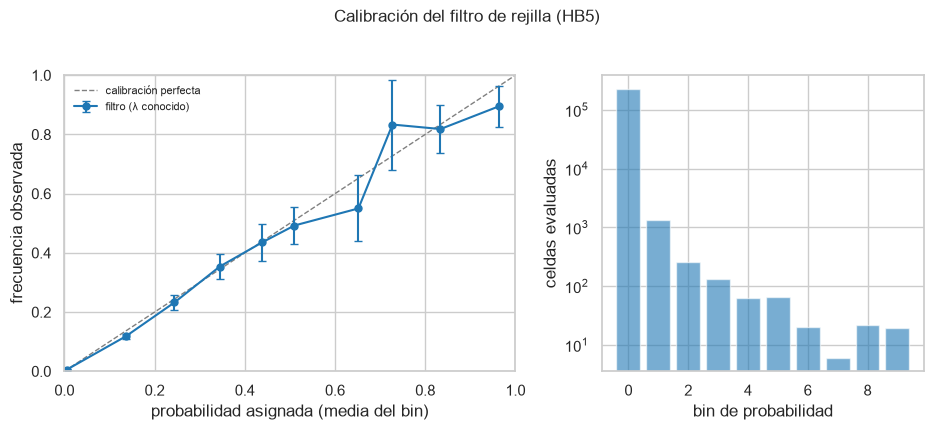

In [27]:
an.fig_calibracion();

**Lectura.** HB2 pasa sin una sola corrida distinta (tabla de controles de la §11), HB3, HB4 y
HB5 se confirman, y HB1, que era la hipótesis central del paquete, se rechaza:

- **HB1, rechazada:** `BAYESIAN` no supera a `KNOWLEDGE_BASED` en ninguna celda, y queda
  claramente por debajo con `r=3` y λ=0.5 (−16.0 ± 4.3) y con visión total a λ=0.25
  (−14.0 ± 5.5); frente al lazo cerrado, en cambio, queda a la par en casi todo el rango (de
  −4.7 ± 5.7 a +5.3 ± 2.4 con `r=3`).
- **HB3, confirmada:** La mediana de $|\hat\lambda-\lambda|$ es 0.083 con `r=1`, 0.020 con `r=3`
  y 0.003 con `r=∞`, de forma que con más visión hay más ensayos y λ se aprende casi exacto,
  mientras que con `r=1` y λ=0 la media posterior queda en 0.16, porque el prior uniforme pesa
  sobre pocos ensayos. Vale la pena anotar que la ley $1/\sqrt{n}$ en sí no se midió, porque el
  barrido no guarda el número de ensayos de cada corrida.
- **HB4, confirmada:** A λ=0.5 y `r=3`, `BAYESIAN` queda 83.0 ± 10.3 puntos por debajo de
  `MODEL_BASED` (15.3 contra 98.3), de modo que saber cuánto se sabe cierra 5 de los 88 puntos
  que separan al lazo cerrado de no planificar, menos que los 21 que cierra saber solo qué es
  posible.
- **HB5, confirmada:** El filtro está calibrado, ya que la frecuencia observada sigue la diagonal
  en todo el rango, la mayor desviación con muchas celdas es de dos centésimas (en el bin
  0.1–0.2), y los bins altos, con pocas celdas, tienen bandas que alcanzan la diagonal.

El rechazo de HB1 no viene de la creencia sino de la decisión. Con el horizonte `"ahora"` (la
ablación, que deja intacta la elección de objetivo y vuelve la decisión de reparar casi idéntica
al monitor del cerrado) `BAYESIAN` y `KNOWLEDGE_BASED` quedan ambos a la par del lazo cerrado
(§11), de modo que la diferencia entre ellos con `"llegada"` está en la regla de reparación, y la
tabla de mecanismo de la §11 dice en qué dirección: `BAYESIAN` repara de forma proactiva bastante
más que `KNOWLEDGE_BASED` (6.2 contra 2.8 reparaciones a λ=0.1 y 16.3 contra 9.5 a λ=0.5), pasa
más tiempo deliberando (265.1 contra 219.2 ticks a λ=0.5) y desperdicia más ediciones (145.8
contra 97.4). La regla $c < (1-q)(c+k)$ repara cada vez que el recurso probablemente no volverá a
su celda, lo cual es correcto como predicción, pero su contabilidad de costos es incompleta en los
dos lados. Por un lado, trata la reparación como si costara `c` y comprara certeza, cuando el plan
reparado nace desactualizado (el mundo sigue moviéndose durante esos `c` ticks, §2) y una
divergencia nueva puede interrumpirlo (§8); por otro, trata un plan mantenido que falla como si
costara solo la caminata más `c`, cuando al fallar el agente suele haber perdido además de vista
al objetivo, lo cual añade un costo de búsqueda que la regla no modela. La primera omisión empuja
a reparar de más y es la que los datos muestran, mientras que la segunda empujaría en sentido
contrario, de forma que lo prudente es concluir que, tal como está, la regla repara más de lo que
conviene con dinamismo alto, y que la lógica gana justamente porque es más tacaña. Cambiar de
horizonte tampoco la arregla: Con `"ahora"`, `BAYESIAN` sube de 84.3 a 93.7 a λ=0.1 (por encima
de `KNOWLEDGE_BASED` con `"llegada"`, 91.3, aunque por debajo de su versión `"ahora"`, 94.7, y
dentro del ruido: +9.3 ± 6.6), pero baja de 15.3 a 9.3 a λ=0.5 (−6.0 ± 2.6).

### El puente lógica → probabilidad

La sesión de inferencia cierra con el Wumpus probabilístico, cuyo argumento es que, cuando la KB
responde `desconocido` para varias celdas, contar los modelos consistentes (pesados por su
probabilidad) permite elegir la menos riesgosa, que es exactamente la Tarea 5 que la sesión de
agentes lógicos dejaba abierta. Este par de agentes lo pone a prueba en un mundo que se mueve, y
los resultados lo parten en dos niveles: En el de la **creencia** el puente funciona sin pérdida,
ya que el soporte del filtro coincide tick a tick con la región lógica (lo `desconocido` para la
KB es exactamente lo que tiene probabilidad positiva), λ se aprende mirando y el filtro está
calibrado; en el de la **decisión**, en cambio, tener la probabilidad correcta no bastó, porque
una regla de utilidad esperada es tan buena como el modelo de costos con que se evalúa, y aquí
ese modelo omite parte de lo que cuesta actuar. Dicho de otra forma, el experimento no refuta que
la probabilidad sirva para decidir, sino que muestra que el cuello de botella se movió de *qué sé*
a *cuánto cuesta lo que hago con lo que sé*.

La tira de `BAYESIAN`, en el mismo mundo y con el mismo λ que la de la §11, muestra la diferencia
de representación: Donde la lógica sombreaba una región plana, el filtro pinta un mapa de calor
más intenso donde el recurso probablemente está.

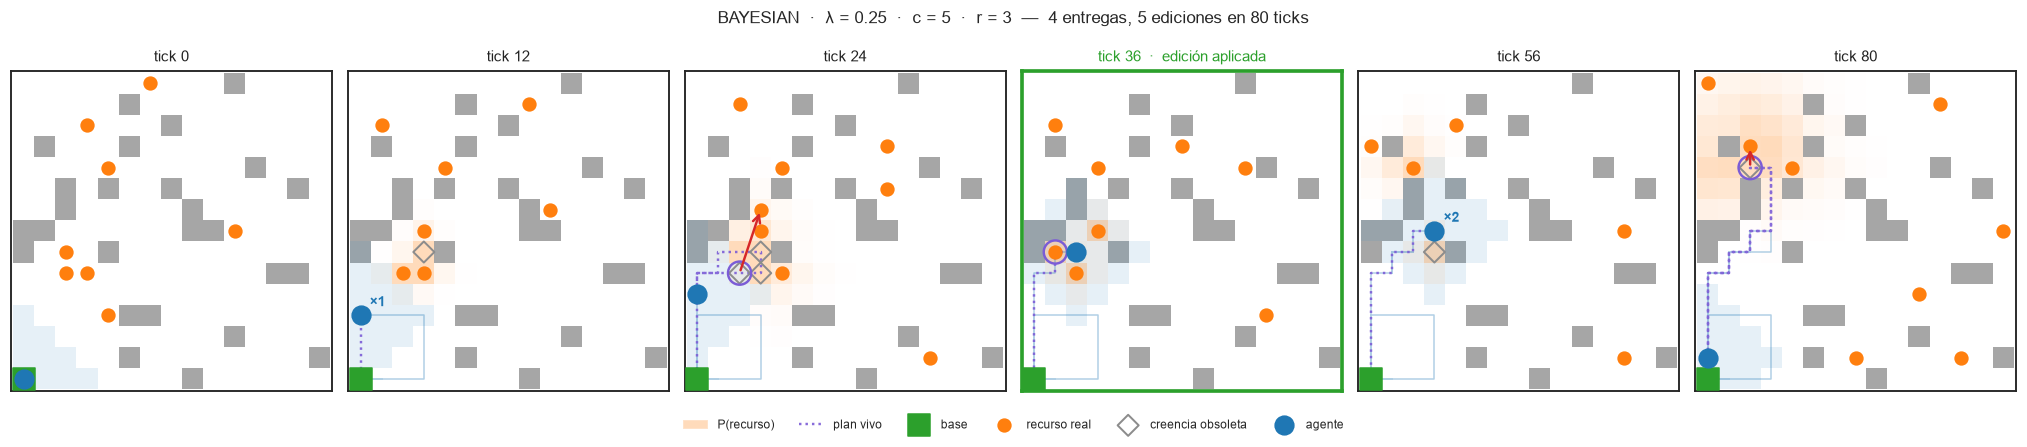

In [28]:
modelo_bayes, frames_bayes = anim.traza_corrida(
    pasos=80,
    policy="BAYESIAN",
    lambda_dinamismo=0.25,
    costo_edicion=5,
    radio=3,
    rng=3,
)
anim.figura_tira(frames_bayes, modelo_bayes, pasos=[0, 12, 24, 36, 56, 80]);

**Lectura.** El filtro concentra la probabilidad alrededor de la última celda vista de cada
recurso y la difumina con el tiempo, de modo que el mapa de calor ocupa la misma zona que la
región de la §11 pero con un centro marcado, que es lo que la regla de reparación consulta al
decidir. El marco verde del tick 36 es una reparación aplicada, y en esta corrida `BAYESIAN`
repara 5 veces y delibera 25 ticks, lo mismo que `CLOSED_LOOP` en el mismo mundo, frente a una
reparación y 8 ticks de `KNOWLEDGE_BASED`, que es en pequeño el patrón de la tabla de mecanismo.

## 13. Escasez: ¿vale más reparar cuando faltan recursos?

En la sesión de predador–presa la tasa de regeneración del pasto fija la capacidad de carga del
sistema, y con ella toda su dinámica. Aquí el número de recursos estuvo fijo en 8 en todos los
barridos, por lo que el experimento no sabía si el valor de replanificar depende de la
abundancia. El barrido se corre en dos regímenes, porque tras la corrección de la regla de costo
ninguna política con plan gana en todo λ con `r=3` y `c=5`:

- **`escasez` (régimen mixto, `r=3`, `c=5`, `p=0.9`):** `MODEL_BASED`, `OPEN_LOOP`,
  `COLD_RESTART`, `CLOSED_LOOP` y `KNOWLEDGE_BASED` (que entra porque su H1 se sostuvo en parte)
  × `n_resources` ∈ {2, 4, 8, 16} × λ × 30 semillas, 2.400 corridas.
- **`escasez_inf` (donde replanificar gana, `r=∞`, `c=0`, `p=1`):** El régimen del control 2,
  con `OPEN_LOOP`, `COLD_RESTART` y `CLOSED_LOOP`, 1.440 corridas.

La celda con 8 recursos de cada régimen reproduce exactamente filas que ya existían (`principal`
y `conocimiento` en el mixto, `control2` en el otro), lo cual sirve de regresión.

**Hipótesis (escrita antes de correr).** Con recursos escasos los viajes entre recogidas son más
largos, el objetivo pasa más tiempo expuesto a la deriva y las divergencias golpean más, por lo
que *la reparación debería valer más con escasez*. Si el resultado fuera el contrario, la
explicación tendría que ver con el costo de oportunidad de deliberar cuando sobran objetivos.

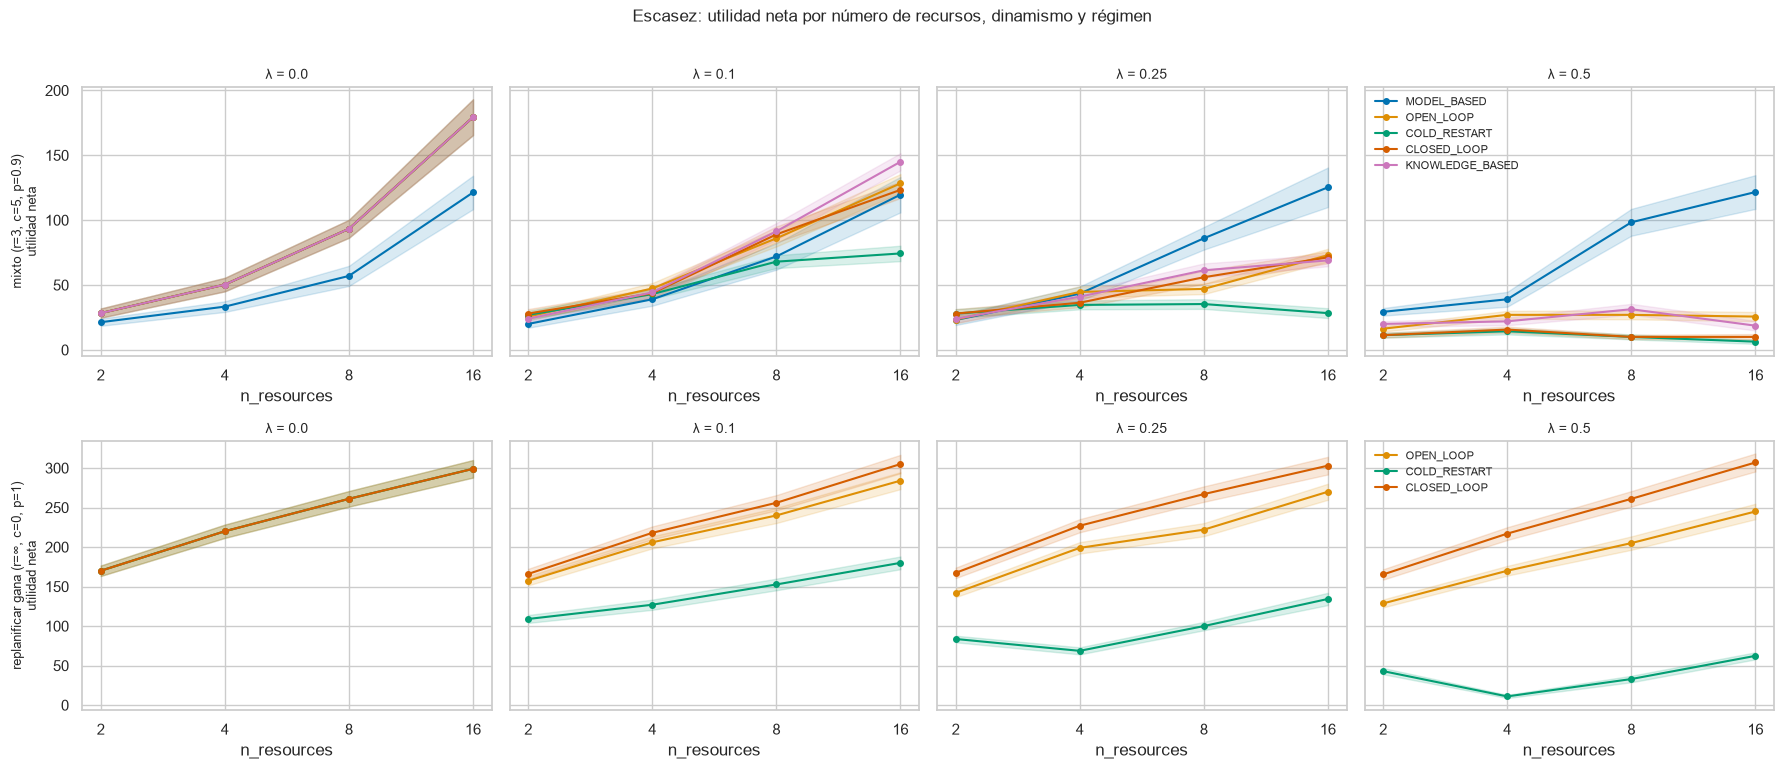

In [29]:
an.fig_escasez();

Las diferencias pareadas que deciden la hipótesis, una columna por número de recursos: primero en
el régimen donde replanificar gana, después en el mixto.

In [30]:
esc = an.cargar("escasez")
inf = an.cargar("escasez_inf")


def por_abundancia(df, pares):
    # Una fila por (contraste, λ) y una columna por número de recursos.
    t = contrastes(df[df["lambda_dinamismo"] > 0], pares, por=("lambda_dinamismo", "n_resources"))
    largo = t.stack().unstack("n_resources")
    largo.index.names = ["lambda_dinamismo", "contraste"]
    return largo.swaplevel().loc[list(pares)]


display(
    por_abundancia(
        inf,
        {"CL − OL": ("CLOSED_LOOP", "OPEN_LOOP"), "CL − CR": ("CLOSED_LOOP", "COLD_RESTART")},
    )
)
por_abundancia(
    esc,
    {
        "CL − OL": ("CLOSED_LOOP", "OPEN_LOOP"),
        "CL − CR": ("CLOSED_LOOP", "COLD_RESTART"),
        "MB − OL": ("MODEL_BASED", "OPEN_LOOP"),
        "MB − CL": ("MODEL_BASED", "CLOSED_LOOP"),
        "KB − CL": ("KNOWLEDGE_BASED", "CLOSED_LOOP"),
    },
)

n_resources                           2             4             8              16
contraste lambda_dinamismo                                                         
CL − OL   0.10                +8.7 ± 3.5   +12.0 ± 4.0   +16.0 ± 4.5    +21.0 ± 4.4
          0.25               +25.3 ± 3.9   +28.0 ± 3.5   +45.0 ± 4.0    +33.0 ± 4.2
          0.50               +36.7 ± 4.0   +47.0 ± 4.0   +56.0 ± 4.3    +62.0 ± 5.0
CL − CR   0.10               +57.0 ± 4.6   +91.0 ± 6.1  +103.3 ± 6.0   +125.0 ± 6.2
          0.25               +83.7 ± 5.2  +158.3 ± 7.3  +167.0 ± 7.6   +168.7 ± 8.7
          0.50              +122.3 ± 6.0  +206.0 ± 7.9  +228.0 ± 9.7  +244.7 ± 10.0

n_resources                          2            4             8              16
contraste lambda_dinamismo                                                       
CL − OL   0.10               +2.3 ± 2.0   -3.7 ± 3.7    +3.0 ± 5.9     -5.0 ± 6.7
          0.25               +4.7 ± 1.8   -8.3 ± 4.3    +9.0 ± 5.7     -1.7 ± 5.5
          0.50               -5.0 ± 2.4  -11.3 ± 3.9   -17.0 ± 3.8    -15.7 ± 3.6
CL − CR   0.10               +1.0 ± 1.0   +0.7 ± 1.2   +21.0 ± 5.3    +49.0 ± 6.8
          0.25               +0.0 ± 0.0   +1.7 ± 1.4   +20.7 ± 5.6    +43.0 ± 5.4
          0.50               +0.0 ± 0.0   +1.3 ± 0.8    +0.0 ± 0.8     +3.7 ± 1.3
MB − OL   0.10               -5.7 ± 3.1   -8.3 ± 6.2  -14.0 ± 10.5    -8.7 ± 13.8
          0.25               -0.3 ± 3.4   -1.3 ± 5.2   +39.0 ± 9.1   +52.3 ± 15.4
          0.50              +13.0 ± 3.1  +12.0 ± 5.6   +71.3 ± 9.6   +96.0 ± 13.0
MB − CL   0.10               -8.0 ± 3.7   -4.7 ± 5.5   -17.0 ± 8.8    -3.7 ± 12.9
          0.25               -5.0 ± 3.9   +7.0 ± 5.1  +30.0 ± 10.1   +54.0 ± 14.8
          0.50              +18.0 ± 3.1  +23.3 ± 6.8  +88.3 ± 10.4  +111.7 ± 12.2
KB − CL   0.10               -4.0 ± 2.4   +0.7 ± 3.9    +2.3 ± 6.1    +21.7 ± 6.7
          0.25               -4.0 ± 2.1   +4.7 ± 4.3    +5.3 ± 6.2     -2.3 ± 4.2
          0.50               +8.7 ± 2.5   +6.3 ± 3.9   +21.3 ± 3.8     +8.7 ± 3.9

Y el mecanismo en el régimen mixto a λ=0.5 (medias por corrida): divergencias, ticks deliberando
y entregas según la abundancia.

In [31]:
(
    esc[esc["politica"].isin(["MODEL_BASED", "OPEN_LOOP", "CLOSED_LOOP"]) & (esc["lambda_dinamismo"] == 0.5)]
    .groupby(["politica", "n_resources"])[["divergencias_reales", "pasos_deliberando", "entregas"]]
    .mean()
    .round(1)
    .unstack("n_resources")
)

divergencias_reales                   pasos_deliberando                      entregas                
n_resources                  2     4     8     16                2      4      8      16       2    4    8     16
politica                                                                                                         
CLOSED_LOOP                32.8  51.0  75.1  78.5             108.6  172.5  282.2  309.8      1.1  1.6  1.0   1.0
MODEL_BASED                 0.0   0.0   0.0   0.0               0.0    0.0    0.0    0.0      2.9  3.9  9.8  12.2
OPEN_LOOP                  16.6  24.4  37.8  42.4              58.5   84.3  153.6  185.4      1.6  2.7  2.7   2.6

**Lectura.** La hipótesis se refuta en los dos regímenes: Reparar vale igual o menos con escasez,
no más.

- **Donde replanificar gana (`r=∞`, `c=0`, `p=1`):** La ventaja del lazo cerrado **crece** con
  la abundancia, de +36.7 ± 4.0 sobre el abierto con 2 recursos a +62.0 ± 5.0 con 16 a λ=0.5 (y de
  +8.7 ± 3.5 a +21.0 ± 4.4 a λ=0.1), y frente al reinicio en frío, de +122.3 ± 6.0 a
  +244.7 ± 10.0.
- **En el régimen mixto (`r=3`, `c=5`, `p=0.9`):** El lazo cerrado no saca una ventaja
  consistente al abierto con λ≤0.25 en ningún número de recursos (los signos alternan entre
  −8.3 ± 4.3 y +9.0 ± 5.7), y a λ=0.5 pierde en todos (de −5.0 ± 2.4 con 2 recursos a
  −15.7 ± 3.6 con 16). Reparar en caliente frente a en frío vale cero con 2 y 4 recursos, porque
  casi no hay carga a bordo que un reinicio pueda tirar (`COLD_RESTART` pierde a lo sumo 0.5
  unidades por corrida), y +43 a +49 con 16 recursos a λ=0.1 y 0.25.
- **No planificar gana más cuanto más abundan los objetivos:** A λ=0.5, la ventaja de
  `MODEL_BASED` sobre el lazo abierto pasa de +13.0 ± 3.1 con 2 recursos a +96.0 ± 13.0 con 16, y
  a λ=0.25 su ventaja sobre el cerrado pasa de −5.0 ± 3.9 a +54.0 ± 14.8, es decir que la
  frontera entre deliberar y no deliberar se corre hacia λ más bajos cuando sobran objetivos (con
  2 y 4 recursos `MODEL_BASED` solo es la mejor política a λ=0.5, y con 8 y 16, desde λ=0.25).
  Con λ=0 pierde en todo número de recursos (de −7.0 a −58.0), como en la §4.
- **`KNOWLEDGE_BASED` mantiene su ventaja a λ=0.5 en toda abundancia:** +8.7 ± 2.5, +6.3 ± 3.9,
  +21.3 ± 3.8 y +8.7 ± 3.9 sobre el lazo cerrado con 2, 4, 8 y 16 recursos, lo cual extiende el
  resultado de H1 de la §11.

La explicación es la que la hipótesis dejaba escrita para el caso contrario, es decir, el **costo
de oportunidad**: Con objetivos escasos el cuello de botella es encontrar y alcanzar un recurso,
y un tick deliberando cuesta poco porque de todos modos no había otra entrega cerca, mientras que
con objetivos abundantes cada tick quieto es una entrega que se deja de hacer. La tabla de
mecanismo lo muestra desde el otro lado, ya que con más recursos los planes encadenan más
objetivos, cada uno es una divergencia posible (a λ=0.5 el lazo cerrado pasa de 32.8 divergencias
reales con 2 recursos a 78.5 con 16) y los ticks deliberando suben con ellas (de 108.6 a 309.8),
justo cuando cada tick vale más, de forma que el lazo cerrado entrega lo mismo (alrededor de un
recurso) con 2 que con 16 recursos, mientras que `MODEL_BASED` pasa de 2.9 a 12.2 entregas. Donde
deliberar es gratis (`c=0`) no hay costo de oportunidad que pagar, y por eso en ese régimen la
abundancia favorece a quien repara.

## 14. Sensibilidad: qué parámetro mueve qué

Sin correr nada nuevo, los cuatro barridos factoriales originales permiten preguntar qué
parámetro mueve más la utilidad de cada política. Para cada barrido y cada política se calcula la
fracción de la varianza de `utilidad_neta` que explica cada factor barrido (η² de un factor,
$SS_{\text{entre}}/SS_{\text{total}}$, es decir, la varianza que desaparece al reemplazar cada
corrida por la media de su nivel), y lo mismo para la diferencia pareada por semilla
`OPEN_LOOP − CLOSED_LOOP`, que es la pregunta del proyecto. Lo que ningún factor explica es
interacción entre factores más la variabilidad del mundo que fija cada semilla (el mapa de
obstáculos y la posición inicial de los recursos).

**Hipótesis (escritas antes de calcular).** (1) λ domina la varianza de toda política con plan;
(2) `c` explica más que `p` la diferencia `OPEN_LOOP − CLOSED_LOOP`; (3) `r` mueve el nivel de
todas las políticas (η² alto en cada una) pero poco su diferencia.

In [32]:
eta = sens.tabla_sensibilidad()
(
    eta.pivot_table(index=["barrido", "politica"], columns="factor", values="eta2", sort=False)
    .rename(columns=sens.ETIQUETAS)
    .round(3)
)

factor                       c (costo de edición)  λ (dinamismo)  p (competencia)  r (radio de visión)  B (presupuesto)
barrido        politica                                                                                                
principal      REFLEX                       0.000          0.043              NaN                  NaN              NaN
               MODEL_BASED                  0.000          0.094              NaN                  NaN              NaN
               OPEN_LOOP                    0.144          0.121              NaN                  NaN              NaN
               COLD_RESTART                 0.104          0.305              NaN                  NaN              NaN
               CLOSED_LOOP                  0.122          0.186              NaN                  NaN              NaN
               GOVERNED                     0.122          0.186              NaN                  NaN              NaN
competencia    OPEN_LOOP                      NaN          0.479            0.015                  NaN              NaN
               COLD_RESTART                   NaN          0.594            0.004                  NaN              NaN
               CLOSED_LOOP                    NaN          0.551            0.002                  NaN              NaN
               GOVERNED                       NaN          0.551            0.002                  NaN              NaN
observabilidad OPEN_LOOP                      NaN          0.286              NaN                0.254              NaN
               COLD_RESTART                   NaN          0.397              NaN                0.046              NaN
               CLOSED_LOOP                    NaN          0.356              NaN                0.154              NaN
               GOVERNED                       NaN          0.356              NaN                0.154              NaN
gobernanza     CLOSED_LOOP                    NaN          0.618              NaN                  NaN            0.000
               GOVERNED                       NaN          0.550              NaN                  NaN            0.003

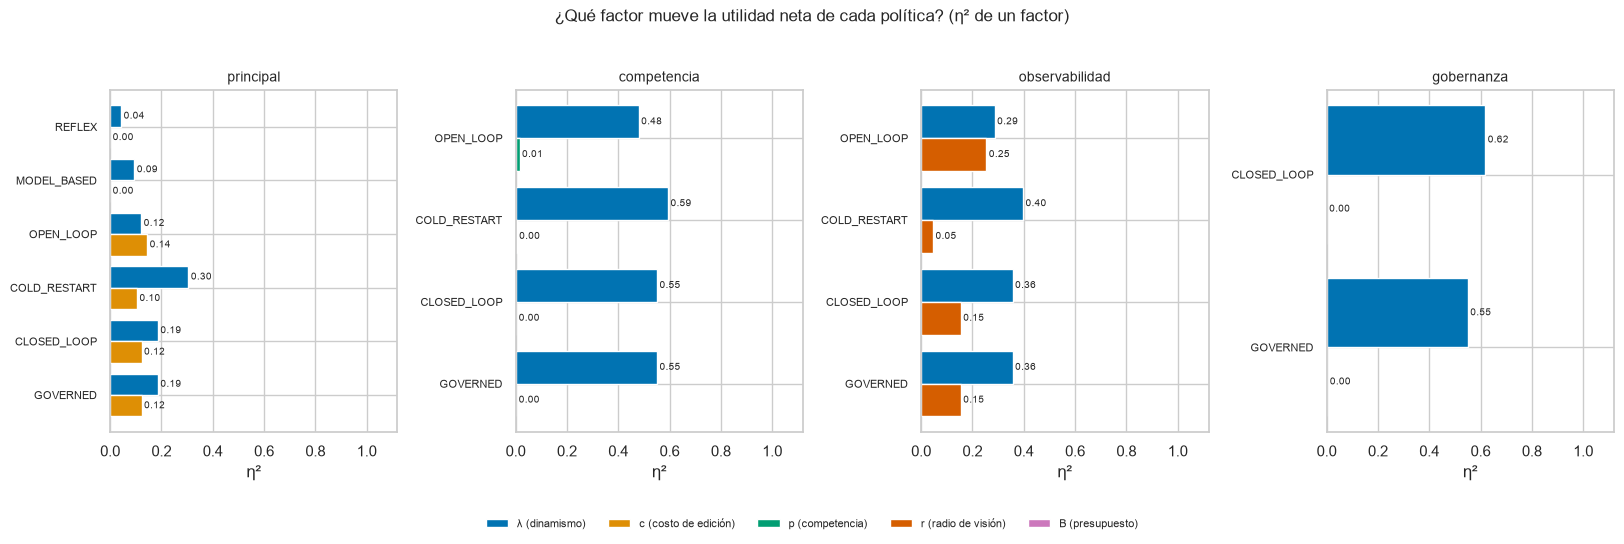

In [33]:
sens.fig_sensibilidad(tabla=eta);

La misma descomposición sobre la diferencia pareada: arriba, el η² de cada factor; abajo, la
diferencia media (± error estándar) en cada nivel, que dice hacia dónde la empuja.

,barrido,contraste,factor,eta2,eta2_parcial
0,principal,OPEN_LOOP − CLOSED_LOOP,lambda_dinamismo,0.014,0.014
1,principal,OPEN_LOOP − CLOSED_LOOP,costo_edicion,0.010,0.010
2,competencia,OPEN_LOOP − CLOSED_LOOP,lambda_dinamismo,0.068,0.069
3,competencia,OPEN_LOOP − CLOSED_LOOP,competencia,0.016,0.017
4,observabilidad,OPEN_LOOP − CLOSED_LOOP,lambda_dinamismo,0.093,0.100
5,observabilidad,OPEN_LOOP − CLOSED_LOOP,radio,0.079,0.087


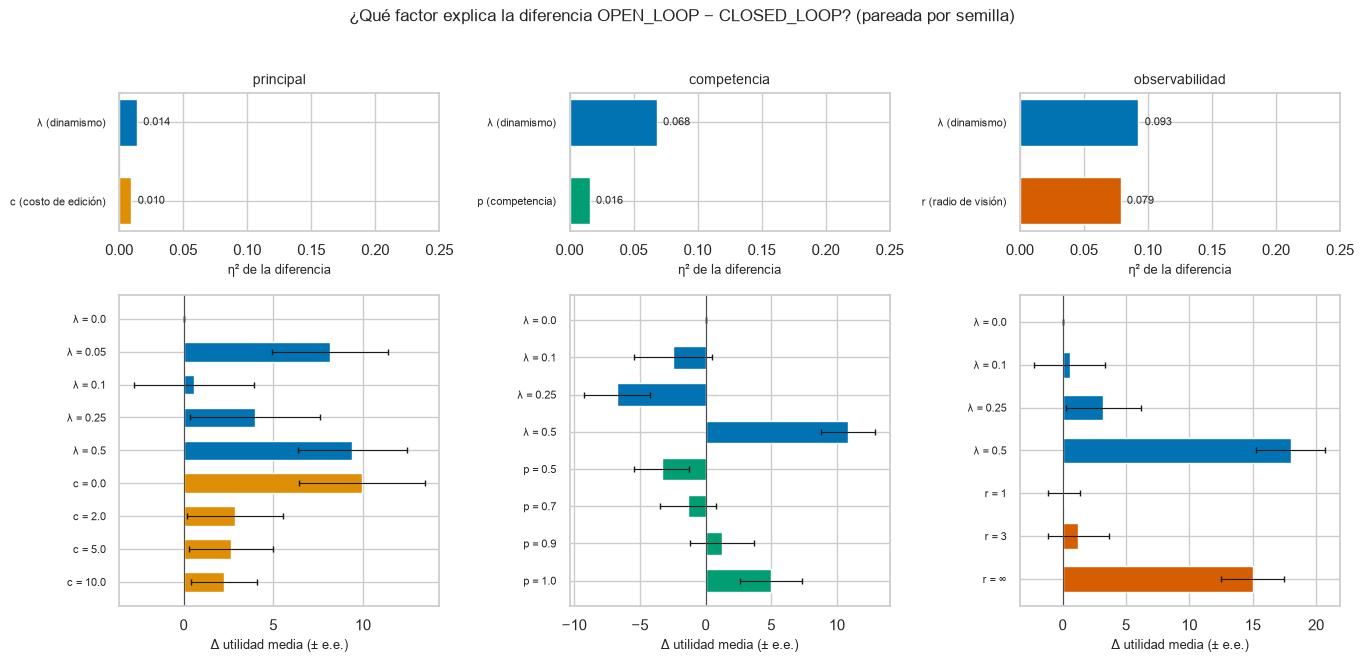

In [34]:
eta_delta, medias_delta = sens.tabla_sensibilidad_delta()
display(eta_delta.round(3))
sens.fig_sensibilidad_delta(tabla=eta_delta, medias=medias_delta);

**Lectura.** Las tres hipótesis, en orden:

- **(1) λ domina a las políticas con plan, con una excepción:** En `competencia`,
  `observabilidad` y `gobernanza`, λ explica entre el 29 % y el 62 % de la varianza de cada
  política, muy por encima de `p` (a lo sumo 1.5 %), `r` (entre 5 % y 25 %) y `B` (a lo sumo
  0.3 %). En `principal` domina también en `COLD_RESTART` (0.305 contra 0.104 de `c`) y en
  `CLOSED_LOOP` (0.186 contra 0.122), pero en `OPEN_LOOP` gana `c` por poco (0.144 contra 0.121).
  `REFLEX` y `MODEL_BASED` tienen η² exactamente 0 para `c`, como debe ser en políticas que nunca
  deliberan, lo cual sirve de control.
- **(2) `c` no explica más que `p` la diferencia entre lazo abierto y cerrado, porque ninguno
  explica casi nada:** Todos los η² de `OPEN_LOOP − CLOSED_LOOP` quedan por debajo de 0.10 (en
  `principal`, 0.014 para λ y 0.010 para `c`; en `competencia`, 0.068 para λ y 0.016 para `p`),
  de modo que la mayor parte de la variación de esa diferencia es ruido entre semillas y mapas,
  que es la contraparte estadística de la conclusión de la §4. Donde sí se mueve es en los
  extremos: Con `c=0` la diferencia media es +9.9 ± 3.5, frente a entre +2.3 y +2.9 en los otros
  niveles; con λ=0.5 en `competencia`, +10.8 ± 2.1; y con `r=∞`, +15.0 ± 2.5, frente a +0.1 y
  +1.3 con `r=1` y `r=3`.
- **(3) `r` mueve el nivel pero poco la diferencia, a medias:** `r` explica un 25 % de la
  varianza del lazo abierto y un 15 % del cerrado, pero solo un 5 % del reinicio en frío, y sobre
  la diferencia explica un 8 %, concentrado en el salto a visión total.

Vale la pena anotar lo que dice el conjunto: En las políticas con plan, los factores barridos
dejan sin explicar entre el 38 % (`CLOSED_LOOP` en `gobernanza`) y el 74 % (`OPEN_LOOP`
en `principal`) de la varianza, que se reparte entre interacciones (λ×`c` es justamente la
frontera) y la variabilidad del mundo, por lo que comparar políticas por pares de semilla, como
hace todo este cuaderno, no es un lujo. Y para la pregunta práctica de qué medir en un despliegue,
la respuesta es λ, que es el parámetro que más mueve a toda política con plan y el que decide
entre planificar y no planificar, mientras que `p` apenas vale la pena medirlo, lo cual la §15
confirma desde otro ángulo.

## 15. Calibración por ABC: estimar λ y p de un despliegue

El guion del proyecto asigna al sistema propio el papel de aportar «λ y p de producción», y la
calibración por ABC de rechazo (*Approximate Bayesian Computation*, la de la sesión de
inferencia, que se remonta a Beaumont et al., 2002) vuelve eso un procedimiento en cuatro pasos:

1. **El despliegue:** Un motor corre `OPEN_LOOP` (el modo en frío y sin monitoreo, que es lo que
   ejecuta un motor sin reparación en caliente) con `c=5`, `r=3` y (λ\*, p\*) ocultos, y su
   telemetría da cinco estadísticos, todos como tasas por tick: entregas, tareas fallidas,
   replanificaciones forzadas, divergencias reales y ticks deliberando. El «dato observado» es su
   media sobre cinco semillas que no pertenecen a ningún barrido.
2. **La tabla de referencia:** Se muestrean 3.000 pares (λ, p) de un prior uniforme, λ ∈ [0, 0.8]
   y p ∈ [0.5, 1], y cada muestra se simula con dos semillas propias (`results/abc.parquet`).
3. **El rechazo:** Se estandariza cada estadístico por su desviación en la tabla y se acepta el
   5 % de muestras (150) más cercano al dato, que aproxima la posterior P(λ, p | telemetría).
4. **La recomendación:** Bajo esa posterior se lee qué política recomienda la frontera ya
   barrida, en dos etapas: «¿planificar o no?» se lee de `principal`, que es el único barrido que
   compara contra las políticas sin plan (y solo usa λ), y si la ganadora planifica, «¿abierto o
   cerrado?» se lee de `competencia` en (λ, p).

Cabe mencionar que el prior de λ llega a 0.8 a propósito, ya que con el prior cortado en 0.5 el
despliegue con λ\*=0.5 quedaba en el borde y la mediana salía 0.39, porque la posterior solo podía
repartirse hacia abajo; el precio es que para λ>0.5 la recomendación extrapola desde la última
columna de los barridos.

**Hipótesis (escrita antes de correr).** λ se recupera con precisión, porque las divergencias y
los fallos lo delatan casi linealmente, mientras que `p` sale mucho más ancha, porque con
`OPEN_LOOP` el oráculo solo se consulta tras un fallo y sus errores se confunden con el
dinamismo.

In [35]:
ref = cal.cargar_referencia()
print(f"{len(ref)} muestras del prior; estadísticos por tick: {', '.join(cal.ESTADISTICOS)}")
ref.describe().loc[["mean", "std", "min", "max"]].round(3)

3000 muestras del prior; estadísticos por tick: entregas, tareas_fallidas, n_ediciones_por_fallo, divergencias_reales, pasos_deliberando


,lam,p,entregas,tareas_fallidas,n_ediciones_por_fallo,divergencias_reales,pasos_deliberando
mean,0.398,0.750,0.012,0.061,0.059,0.075,0.297
std,0.231,0.144,0.018,0.026,0.025,0.037,0.128
min,0.000,0.500,0.000,0.000,0.000,0.000,0.000
max,0.800,1.000,0.259,0.115,0.114,0.140,0.569


Las tres calibraciones de demostración, con (λ\*, p\*) conocidos para poder juzgar el resultado:
cada una simula el despliegue (cinco corridas), aplica el rechazo y lee la recomendación.

In [36]:
filas, recomendaciones = [], {}
for lam, p in cal.TRUTHS_DEMO:
    resultado, rec = cal.demo(lam, p, ref)
    ic = resultado.intervalos
    combinada = rec[rec["fuente"] == "combinada"].sort_values("fraccion", ascending=False)
    filas.append(
        {
            "(λ*, p*)": f"({lam}, {p})",
            "λ: mediana [IC 90 %]": (
                f"{ic.loc['lam', 'q50']:.2f} [{ic.loc['lam', 'q05']:.2f}, {ic.loc['lam', 'q95']:.2f}]"
            ),
            "p: mediana [IC 90 %]": (
                f"{ic.loc['p', 'q50']:.2f} [{ic.loc['p', 'q05']:.2f}, {ic.loc['p', 'q95']:.2f}]"
            ),
            "recomendación combinada": ", ".join(
                f"{pol} {f:.0%}" for pol, f in zip(combinada["politica"], combinada["fraccion"])
            ),
        }
    )
    recomendaciones[(lam, p)] = rec
pd.DataFrame(filas).set_index("(λ*, p*)")

,λ: mediana [IC 90 %],p: mediana [IC 90 %],recomendación combinada
"(λ*, p*)",,,
"(0.1, 0.9)","0.06 [0.01, 0.14]","0.76 [0.52, 0.98]","CLOSED_LOOP 81%, OPEN_LOOP 15%, MODEL_BASED 3%"
"(0.25, 0.7)","0.25 [0.15, 0.40]","0.75 [0.53, 0.96]","MODEL_BASED 87%, CLOSED_LOOP 8%, OPEN_LOOP 5%"
"(0.5, 0.9)","0.45 [0.29, 0.74]","0.75 [0.54, 0.95]",MODEL_BASED 100%


La posterior conjunta del caso intermedio, (λ\*, p\*) = (0.25, 0.7): en gris el prior simulado,
en azul las muestras aceptadas y la estrella en el valor verdadero; las líneas punteadas de las
marginales marcan el intervalo creíble del 90 %.

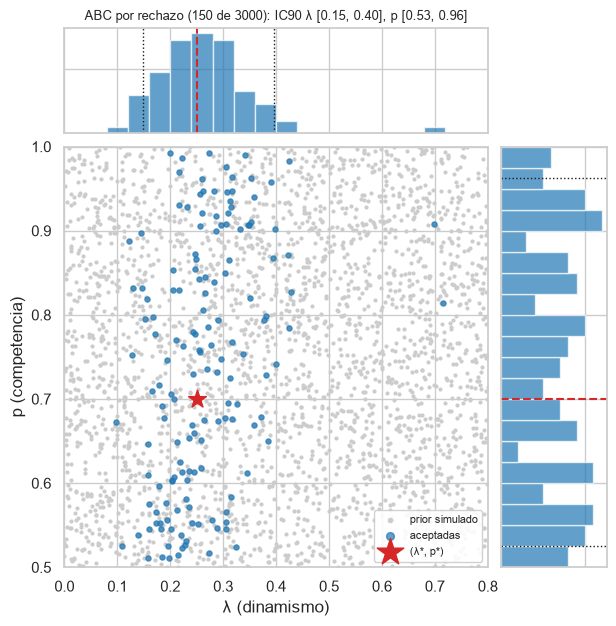

In [37]:
cal.fig_abc(0.25, 0.7, tabla=ref);

Y las tres lecturas de la recomendación para ese mismo caso, que muestran por qué hace falta la
decisión en dos etapas.

In [38]:
(
    recomendaciones[(0.25, 0.7)]
    .pivot(index="politica", columns="fuente", values="fraccion")
    .fillna(0)
    .round(2)
)

fuente,combinada,"competencia (λ, p)",principal (λ)
politica,,,
CLOSED_LOOP,0.08,0.79,0.13
MODEL_BASED,0.87,0.00,0.87
OPEN_LOOP,0.05,0.21,0.00


**Lectura.** La hipótesis se cumple para λ y se queda corta para `p`:

- **λ se recupera:** El valor verdadero cae dentro del intervalo creíble del 90 % en los tres
  casos, con medianas de 0.06, 0.25 y 0.45 para λ\* = 0.1, 0.25 y 0.5, aunque la precisión es
  moderada y empeora con λ (los intervalos miden 0.13, 0.25 y 0.45 de ancho).
- **`p` no es identificable con esta telemetría:** Las tres posteriores de `p` son prácticamente
  el prior, ya que un uniforme en [0.5, 1] tiene mediana 0.75 y cuantiles del 5 % y del 95 % en
  0.525 y 0.975, y las posteriores dan 0.76 [0.52, 0.98], 0.75 [0.53, 0.96] y 0.75 [0.54, 0.95].
  La hipótesis esperaba una posterior ancha, pero lo que hay es ninguna información, lo cual
  cuadra con la §6 y la §14 (η² de `p` ≤ 0.015): Un parámetro que casi no mueve el resultado
  tampoco deja huella en la telemetría que lo resume.
- **La recomendación sí es útil:** Con λ\*=0.1 la combinada recomienda planificar
  (`CLOSED_LOOP` 81 %, `OPEN_LOOP` 15 %), con λ\*=0.25 no planificar (`MODEL_BASED` 87 %) y con
  λ\*=0.5 no planificar con certeza (100 %). La tabla de las tres fuentes muestra por qué hace
  falta la decisión en dos etapas, dado que leída solo en `competencia`, que no tiene políticas
  sin plan, la recomendación del caso intermedio sería `CLOSED_LOOP` (79 %), mientras que
  `principal` dice que en ese dinamismo conviene no planificar (87 %). Vale la pena leer con
  cuidado el primer caso, ya que el 81 % de `CLOSED_LOOP` sale de diferencias con el lazo
  abierto que la §6 deja dentro del ruido a λ=0.1 (+3.0 ± 5.9 con `p=0.9`), por lo que lo que la
  calibración respalda ahí es «planificar», más que «monitorear».

La lectura operativa es la que el guion pedía al sistema propio: Con la telemetría de un motor en
frío se puede estimar λ y, con él, decidir si conviene planificar, pero no se puede estimar la
competencia del replanificador, para la cual habría que etiquetar cada reparación contra la
óptima, cosa que esa telemetría no registra. Por suerte, la decisión que más importa (planificar o
no) depende de λ y no de `p`. Quedan dos salvedades, dado que el despliegue es sintético (lo
genera el mismo modelo que la tabla de referencia), así que el ejercicio muestra que el
procedimiento identifica λ cuando el modelo es correcto y no que el modelo describa un motor
real, y que para λ>0.5 la recomendación extrapola.

## 16. ¿Por qué la frontera tiene esa forma?

La pieza pedagógica más fuerte de la sesión de predador–presa es su sección sobre qué hace
estable al sistema, que primero diagnostica por qué moría todo y después enumera los mecanismos
que lo sostienen (el recurso renovable, el acoplamiento débil, la respuesta con retardo y los
amortiguadores). La misma estructura sirve para explicar la frontera λ–c de la §4 como un sistema
y no figura por figura, con una advertencia que conviene dejar escrita al principio: El paralelo
con predador–presa es una **analogía y no un mecanismo**, dado que el modelo no tiene poblaciones
acopladas ni ciclos (la §10 no encontró ninguna oscilación), de modo que cada pilar se usa para
ordenar la explicación y se rotula como analogía o como mecanismo, y la evidencia sale de los
barridos del proyecto y no de Lotka–Volterra. Las cifras son con `p=0.9` y `r=3` salvo que se
diga otra cosa.

1. **El diagnóstico, deliberar se come el tiempo** *(mecanismo)*. Con `c=0` el lazo abierto es la
   mejor política o empata en todo λ (120.3 contra 110.7 del cerrado a λ=0.5, y 96.0 contra 96.0
   a λ=0.1), pero desde `c=2` y λ≥0.25 la mejor pasa a ser `MODEL_BASED`, que actúa sobre sus
   creencias sin plan y nunca paga deliberación (a λ=0.5 y `c=5` rinde 98.3, frente a 27.0 del
   lazo abierto y 10.0 del cerrado, §4). La razón se lee en el mecanismo, ya que en esa celda
   `CLOSED_LOOP` pasa 282.2 de sus 400 ticks deliberando y `OPEN_LOOP` 153.6, y la §10 muestra que
   ese impuesto se cobra desde el principio (`MODEL_BASED` se separa del cerrado desde el tick
   15). El frente que importa con dinamismo alto ya no es entonces «comprometerse frente a
   reparar» sino «planificar frente a no planificar», y es el resultado más estable del trabajo,
   pues sobrevive al orden de activación (§9) y se ensancha con la abundancia de objetivos (§13).
   Entre las dos políticas con plan, en cambio, la distancia es pequeña y de signo variable (89.0
   contra 86.0 a favor del cerrado a λ=0.1 con `c=5`), ningún factor la explica (η² ≤ 0.09, §14)
   y su signo cambia al sortear el orden (§9).
2. **La observabilidad, un desplazador y no el diagnóstico** *(mecanismo)*. El radio mueve sobre
   todo el nivel de utilidad de todas las políticas (promediando λ con `c=5`, `CLOSED_LOOP` pasa
   de 47.9 con `r=1` a 114.5 con `r=∞` y `OPEN_LOOP` de 48.0 a 129.5, §7), mientras que la
   ventaja del lazo abierto sobre el cerrado es casi nula con `r=1` y `r=3` (48.0 contra 47.9 y
   63.3 contra 62.1) y moderada con visión total (+15.0 ± 2.5, §14). La creencia obsoleta existe,
   pues sin ver el objetivo el oráculo recibe `true_goal=None` y repara hacia la creencia aunque
   su sorteo de competencia salga a favor (§6), y afecta también al lazo abierto, que replanifica
   por el mismo oráculo, lo cual se ve en que subir `p` de 0.5 a 1.0 a λ=0.25 mueve más al
   abierto (36.7 a 61.0) que al cerrado (48.3 a 59.7). Pero la §11 la puso a prueba directamente
   y no es lo que hunde a las políticas con plan, ya que las preguntas lógicas que la atacan
   (descartar candidatos vistos vacíos y elegir objetivo por el peor caso) no compran nada
   medible por sí solas (ablación con `"ahora"`: +5.7 ± 4.1, −3.0 ± 5.1 y −1.3 ± 2.6 sobre el
   cerrado, figura de conocimiento de la §11), y lo único que ayuda es dejar de pagar
   reparaciones, que es otra vez el pilar 1.
3. **Respuesta con retardo** *(analogía con la reproducción lenta del predador; el retardo en sí
   es mecanismo del modelo)*. Deliberar ocupa `c` ticks y el plan se calcula al empezar y se
   retiene, de modo que llega desactualizado si el mundo se movió mientras tanto (§2), y la
   figura de la dinámica (§10) lo hace visible en el tiempo, pues las entregas acumuladas son casi rectas, con pendientes que
   fija λ, y los ticks deliberando también. Es aquí donde la analogía se rompe, ya que en
   Lotka–Volterra el retardo produce ciclos, mientras que en este modelo no hay retroalimentación
   del agente sobre el mundo que pueda producirlos, y el retardo se traduce en un impuesto de
   ritmo constante en vez de una oscilación.
4. **El *thrashing* de replanificación** *(mecanismo)*. Cada divergencia nueva interrumpe la
   deliberación en curso y los ticks gastados se pierden, lo cual con `r=∞`, `c=5` y λ=0.5 deja a
   `CLOSED_LOOP` en utilidad 0.0, frente a 34.0 del lazo abierto, que también delibera tras cada
   fallo pero no se deja interrumpir (§7), y en el Avance 2, con visión total y replanificador
   exacto, bastó `c=1` para invertir la ventaja (79.8 contra −11.3 a λ=0.5). El agente basado en
   conocimiento lo recorta por la vía lógica con `r=3` (97.4 ediciones desperdiciadas contra
   181.8 a λ=0.5, y +21.3 ± 3.8 de utilidad, §11), pero con visión total no le alcanza (5.0
   contra 34.0 del abierto, con 211.5 ediciones desperdiciadas).
5. **Amortiguadores** *(analogía con el tope de energía del predador)*. Un presupuesto pequeño de
   ediciones recorta el *thrashing*, aunque bastante menos de lo que se creía: A λ=0.5,
   `GOVERNED` con `B=3` rinde 23.7 contra 10.0 de `CLOSED_LOOP` y sus ediciones desperdiciadas
   caen de 181.1 (con `B=25`) a 50.7, pero con `B=0`, que es exactamente `OPEN_LOOP` (control 6),
   rinde 27.0 con 10.1 desperdiciadas (§8), y el horizonte lógico de la §11, que es otro
   amortiguador, rinde lo mismo que no reparar de forma proactiva (+4.3 ± 5.3 sobre el abierto).
   Con dinamismo alto, el mejor amortiguador medido es entonces no reparar de forma proactiva, y
   el presupuesto explica menos del 0.3 % de la varianza (§14).
6. **Capacidad de carga** *(analogía con el pasto que se repone)*. Cada entrega repone un
   recurso, así que el mundo nunca se queda sin trabajo, y la figura de escasez (§13) midió si la
   abundancia cambia el valor de replanificar: Lo cambia, pero al revés de lo esperado, ya que con más objetivos crece
   la ventaja del cerrado donde replanificar es gratis (de +36.7 ± 4.0 a +62.0 ± 5.0 sobre el
   abierto a λ=0.5, con `r=∞`, `c=0` y `p=1`) y crece la de no planificar donde cuesta (de
   +13.0 ± 3.1 a +96.0 ± 13.0 sobre el abierto a λ=0.5, con `c=5`). La analogía vale solo en que
   la abundancia fija la escala, pues el mecanismo es el costo de oportunidad: Cuando sobran
   objetivos, cada tick deliberando es una entrega que se deja de hacer.

**La corrección que cambió esta lectura.** Vale la pena dejarla escrita aquí también: Antes de
la corrección de la regla de costo (nota del inicio) la replanificación tras un fallo era gratuita
y con A\* exacto, mientras que la reparación proactiva pagaba `c` y pasaba por el oráculo, de
modo que el experimento comparaba una reparación pagada contra una gratuita, y buena parte de la
dominancia del lazo abierto (así como del «rescate» por gobernanza) era artefacto de esa
asimetría. Hoy un fallo del plan solo deja pendiente la replanificación (`Collector._fallar_tarea`)
y el tick siguiente la dispara por el mismo oráculo y al mismo costo que cualquier reparación
(`_iniciar_deliberacion(por_fallo=True)`), sin consumir presupuesto, lo cual hace de `B=0` un
control exacto: `GOVERNED` ≡ `OPEN_LOOP` en 180 pares de corridas, sin una sola distinta (§3).

**Dos referencias para leer la frontera.** R&N §11.5 presenta el monitoreo de ejecución y la
replanificación como la respuesta a un mundo que no se comporta como el plan supone, y este
trabajo la matiza en vez de contradecirla, ya que monitorear compensa cuando reparar es barato y
bueno (control 2) y deja de compensar en cuanto reparar cuesta tiempo en un mundo que no espera.
Brooks (1991), por su parte, sostenía que un agente puede prescindir de representaciones y planes
y dejar que el mundo sirva como su propio modelo, y el régimen de λ alto y `c≥2` de este modelo
es justamente el lugar donde no planificar gana, con dos salvedades: El ganador (`MODEL_BASED`)
no es puramente reactivo, pues mantiene creencias, y lo que aparece no es una postura general sino
una región del espacio de parámetros.

Así, en una frase coherente con los datos: *Cuando reparar cuesta, el lazo abierto y el cerrado
quedan cerca y, con el entorno cambiando rápido, gana el agente que no delibera, tanto más cuanto
más abundan los objetivos; la observabilidad parcial mueve sobre todo el nivel de utilidad; el
thrashing es real y un presupuesto pequeño o un horizonte lógico lo recortan, aunque con dinamismo
alto no reparar de forma proactiva lo recorta igual; y reparar en caliente frente a reiniciar en
frío compensa en casi todo el rango con λ>0, salvo a λ=0.5 con `c≥5`, donde ambas políticas
colapsan.*

## 17. Conclusiones

Antes de las conclusiones, una nota de método: Las cifras que siguen salen del barrido vuelto a
correr tras corregir la regla de costo (nota del inicio) y de los barridos que se añadieron
después con la regla ya corregida (16.260 corridas en total), y varias conclusiones de la versión
anterior (el dominio del lazo abierto bajo observabilidad parcial, la observabilidad como la
variable que lo decide todo y el presupuesto como la diferencia entre funcionar y no funcionar)
no sobrevivieron a la corrección, de forma que se reescribieron a partir de los datos nuevos. El
cuadro que queda es más matizado, y con 30 réplicas por combinación varias de las diferencias
entre políticas caen dentro del error estándar, lo cual se indica en cada caso, del mismo modo que
se indican las hipótesis que los datos rechazaron.

1. **Con el mismo replanificador al mismo precio, reparar al ver la divergencia y esperar a que
   el plan falle casi empatan.** Con `r=3`, la diferencia entre `OPEN_LOOP` y `CLOSED_LOOP` va
   de −9 a +26 puntos según λ y `c`, y en 13 de las 16 celdas dinámicas queda dentro de dos
   errores estándar; ningún factor barrido explica más del 10 % de su varianza (§14) y su signo
   cambia en la mitad de las celdas al sortear el orden de activación (§9), por lo que monitorear
   el plan no compra casi nada sobre replanificar solo al fallar.
2. **La frontera que sí aparece separa deliberar de no deliberar.** Cuando el mundo cambia
   rápido y deliberar es caro, el agente reactivo basado en modelo, que mantiene creencias y
   nunca paga deliberación, es la mejor política (98.3 a λ=0.5 contra 53.3 de la mejor que
   planifica con `c=2`, y 86.0 contra 56.0 a λ=0.25 con `c=5`), de forma que el costo de
   reescritura a partir del cual la ventaja se invierte existe, aunque es el que hace dejar de
   convenir planificar (entre `c=0` y `c=2` a λ=0.5, y entre `c=2` y `c=5` a λ=0.25), y el
   orden de la taxonomía de R&N depende del entorno de tarea. Es la conclusión más estable del
   trabajo, pues sobrevive al orden de activación (5 de 6 celdas, §9), aparece desde los primeros
   ticks (desde el tick 15 a λ=0.5, §10) y crece con la abundancia de objetivos (a λ=0.5, de
   +13.0 ± 3.1 con 2 recursos a +96.0 ± 13.0 con 16, §13).
3. **Reparar en caliente vale claramente más que reiniciar en frío desde λ=0.1,** con +16 a +22
   puntos a λ=0.1 y 0.25 cuando `c` está entre 2 y 5, +32 puntos (+41 %) a λ=0.5 con
   deliberación gratuita y hasta +80.7 con visión total, aunque la relación con `c` no es
   monótona y la ventaja se anula donde las dos políticas colapsan (λ=0.5 con `c≥5`). Se mantiene
   positiva con orden de activación sorteado en las seis celdas medidas (§9), pero tarda en pagar
   (solo se separa del ruido desde el tick 105 a 130, cuando hay trabajo en curso que perder,
   §10) y desaparece cuando los recursos escasean (con 2 y 4 recursos, §13).
4. **La observabilidad amplifica lo que decide el costo de deliberar.** Ver más sube el nivel de
   todas las políticas (de 47.0 a 261.0 a λ=0 entre `r=1` y `r=∞`), pero con `c=5` la visión
   total no hace ganar al lazo cerrado (114.5 contra 129.5 del lazo abierto, en promedio sobre
   λ), que solo domina con deliberación gratuita y oráculo perfecto (control 2, +45 y +56 a
   λ=0.25 y 0.5).
5. **Acotar las reparaciones proactivas evita el peor caso, pero no hay una cuota óptima que
   rescate al agente.** A λ=0.5, `GOVERNED` con `B=3` rinde 23.7 contra 10.0 del lazo cerrado
   sin acotar, pero con `B=0` (el lazo abierto) rinde 27.0, y a λ=0.1 y 0.25 el presupuesto
   apenas se nota (η² de `B` ≤ 0.003, §14), por lo que un tope fijo y bajo de iteraciones no es
   la razón por la que el agente funciona.
6. **La competencia del replanificador pesa más sobre quien replanifica menos, y en general
   pesa poco.** Subir `p` de 0.5 a 1.0 lleva al lazo abierto de 36.7 a 61.0 a λ=0.25, y al lazo
   cerrado solo de 48.3 a 59.7, de forma que con un replanificador mediocre monitorear compensa
   parte de sus errores y con uno bueno no hace falta, pero `p` explica a lo sumo el 1.5 % de la
   varianza de cada política (§14) y no deja huella en la telemetría de un motor en frío (§15).
7. **Las políticas se separan por ritmo, no por un evento.** Las entregas acumuladas y los ticks
   deliberando crecen casi en línea recta desde el tick 50, con pendientes que fija λ (§10), de
   modo que el *thrashing* es un impuesto constante y no una crisis, y la analogía con
   predador–presa se rompe justamente ahí: El retardo de la deliberación no produce ciclos.
8. **Saber qué se sabe ayuda solo cuando evita pagar reparaciones, y no alcanza a no
   planificar.** `KNOWLEDGE_BASED` supera al lazo cerrado con el signo esperado en todo el rango,
   pero solo fuera del ruido con `r=3` y λ=0.5 (+21.3 ± 3.8); la ganancia desaparece en la
   ablación con horizonte `"ahora"`, de modo que no viene de elegir mejor el objetivo sino de no
   reparar ante derivas de las que el recurso puede volver; queda por debajo de `MODEL_BASED`
   desde λ=0.25 (−24.7 ± 9.8 y −67.0 ± 10.5); y razonar tiene que ser casi gratis, pues un solo
   tick por consulta invierte la ventaja (§11). La respuesta a la Tarea 4 de la sesión de agentes
   lógicos es que la monotonía no se rompe cuando el mundo se mueve, sino que se indexa por el
   tiempo.
9. **Saber cuánto se sabe no mejoró la decisión.** `BAYESIAN` aprende λ (error mediano de 0.020
   con `r=3`) y su filtro está calibrado y tiene exactamente el soporte de la región lógica, pero
   la hipótesis de que superaría al agente lógico se rechaza (−16.0 ± 4.3 con `r=3` y λ=0.5),
   porque su regla de utilidad esperada repara más de lo que conviene, y queda 83.0 ± 10.3 puntos
   por debajo de `MODEL_BASED` a λ=0.5 (§12). El puente de la lógica a la probabilidad funciona
   en la creencia y falla en la decisión, cuyo modelo de costos resultó ser el eslabón débil.
10. **Reparar vale menos, no más, cuando los recursos escasean.** La hipótesis de que la escasez
    haría más valiosa la reparación se refuta en los dos regímenes: Donde replanificar es gratis,
    la ventaja del lazo cerrado crece con la abundancia (de +36.7 ± 4.0 a +62.0 ± 5.0 a λ=0.5), y
    donde cuesta, crece la de no planificar, lo cual se explica por el costo de oportunidad de
    cada tick deliberando cuando sobran objetivos (§13).
11. **Lo que hay que medir de un despliegue es λ, y se puede medir.** λ es el factor que más
    mueve a toda política con plan (hasta el 62 % de la varianza, §14) y se recupera por ABC
    desde la telemetría de un motor en frío (el valor verdadero cae en el intervalo creíble del
    90 % en los tres casos, §15), lo cual basta para recomendar si planificar o no, mientras que
    `p` no es identificable con esa telemetría ni decisivo para la recomendación.

### Las hipótesis del Avance 2, revisadas

El Avance 2 trabajó con un modelo idealizado (visión total, oráculo perfecto, capacidad 1, sin
`COLD_RESTART`, `GOVERNED` ni `MODEL_BASED`, 10 semillas y 300 ticks), en el que con `c=0` el
lazo cerrado superaba al abierto a λ=0.25 y 0.5 (125 contra 118 y 128 contra 114), con `c=1` el
abierto ganaba en todo λ>0 (79.8 contra −11.3 a λ=0.5), de modo que el cruce quedaba entre `c=0`
y `c=1`, y el reflejo superaba a ambos con λ·c grande. Sus cinco hipótesis para el siguiente paso
quedan así:

| Hipótesis del Avance 2 | Veredicto con el modelo final |
|---|---|
| Con `r` finito el replanificador se degrada y comprometerse resulta mejor | **A medias:** `r` mueve sobre todo el nivel, y la diferencia entre abierto y cerrado es casi nula con `r=1` y `r=3` y moderada con `r=∞` (+15.0 ± 2.5) |
| Con `p<1` existe una calidad mínima desde la cual conviene auto-editarse | **No en la forma esperada:** `p` pesa más sobre quien replanifica menos (36.7 a 61.0 en el abierto frente a 48.3 a 59.7 en el cerrado, a λ=0.25) y explica a lo sumo el 1.5 % de la varianza |
| Con capacidad mayor que 1, reparar en caliente supera a reiniciar en frío | **Sí:** desde λ=0.1 (+16 a +22 con `c` entre 2 y 5, +32 a λ=0.5 con `c=0`, hasta +80.7 con visión total), salvo donde ambas colapsan; es la conclusión más robusta, también al orden de activación |
| Un presupuesto de ediciones amortigua el *thrashing* | **Evita el peor caso pero no rescata:** `B=3` rinde 23.7 contra 10.0 a λ=0.5, pero `B=0` (≡ `OPEN_LOOP`) rinde 27.0, y η² de `B` ≤ 0.003 |
| El barrido completo traza la frontera | **Hecho y extendido:** 16.260 corridas en trece barridos, más 600 series temporales y 3.000 simulaciones de ABC |

Lo que el Avance 2 no anticipó, porque no incluía políticas sin plan, es que la frontera relevante
separa deliberar de no deliberar.

### Límites

- **Escala:** Un solo agente, retícula 15×15 y `T_max=400`, por lo que el régimen multi-agente
  queda fuera.
- **Costo en tokens:** `κ=0` en todos los barridos, de forma que el único castigo por deliberar
  es el tiempo perdido y no el costo en tokens, y con `κ>0` la frontera se desplaza sin que se
  haya medido.
- **Oráculo:** Es una abstracción del LLM con dos modos de fallo, fiel al *tipo* de error pero
  no a su distribución real.
- **Alcance de edición:** Es fijo (solo la entrega final queda fuera del alcance del agente) y
  no se varía en ningún barrido, por lo que su efecto sobre el rendimiento no se ha medido.
- **Réplicas:** Con 30 réplicas por combinación, buena parte de las diferencias entre el lazo
  abierto y el lazo cerrado caen dentro del error estándar (la mayor parte de la varianza de esa
  diferencia es ruido entre semillas, §14), y el control 3 pasa solo por el signo (85.0 contra
  87.5), por lo que conviene leerlo como «el lazo cerrado no mejora» y no como «el lazo cerrado
  empeora».
- **Visión total:** Solo se barrió con `c=5` y `p=0.9`, además del control 2 y de `escasez_inf`
  (ambos con `c=0` y `p=1`), de modo que la frontera en `c` con observabilidad total queda sin
  trazar.
- **Dinámica y orden, en una rebanada:** Las series temporales solo tienen `c=5` y `r=3`, y el
  orden aleatorio solo sortea si el recolector actúa antes o después de la deriva, en un
  subconjunto de `principal` (λ ≥ 0.1 y `c` ∈ {2, 5}).
- **Inferencia gratuita:** Las preguntas de `KNOWLEDGE_BASED` y `BAYESIAN` no cuestan nada por
  defecto, y cuando cada consulta se cobra la ventaja se invierte con un solo tick (§11), de modo
  que el resultado depende de que razonar sea mucho más barato que deliberar, lo cual es
  plausible para operaciones de conjuntos pero no está garantizado en un sistema real. Además, la
  equivalencia entre esas operaciones y DPLL se comprobó solo en una retícula de 4×4.
- **La regla bayesiana:** Su modelo de costos omite que el plan reparado nace desactualizado y
  puede interrumpirse, y que un plan fallido deja al agente sin ver al objetivo, y no se probó una
  regla corregida, de modo que el rechazo de HB1 es el de esta regla y no el de la decisión
  bayesiana en general. El agente, por otra parte, aprende λ pero recibe la forma de la deriva
  (una vecina transitable al azar).
- **Escasez:** Se varió solo el número de recursos, mientras que la capacidad de carga del agente
  (3) y la reposición de cada recurso entregado quedaron fijas, por lo que el análogo del pasto
  que se agota no se probó.
- **Sensibilidad:** Es un η² de un factor, solo sobre los cuatro barridos factoriales originales,
  y las interacciones (λ×`c`, que es la frontera misma) no se descompusieron.
- **ABC:** El despliegue es sintético, la telemetría tiene solo cinco tasas agregadas de un motor
  `OPEN_LOOP` con `c=5` y `r=3` fijos, `p` no es identificable con ella, y para λ>0.5 la
  recomendación extrapola desde los barridos.

## Reproducir

Desde la raíz del repositorio:

```bash
uv run pytest project/tests -q                                   # 278 pruebas (277 pasan, 1 se salta)
uv run python -m project.experiments --smoke                     # barrido de humo (12 corridas, no escribe CSV)
uv run python -m project.experiments --full --procesos 0         # los trece barridos: 16.260 corridas
uv run python -m project.experiments --sweep orden --procesos 0  # o uno solo (lista abajo)
uv run python -m project.experiments --dinamica --procesos 0     # series temporales -> results/dinamica.parquet
uv run python -m project.calibracion --referencia --procesos 0   # tabla de ABC -> results/abc.parquet
uv run python -m project.calibracion --demo --todas --figura     # las tres calibraciones de la §15
uv run python -m project.analysis --controles --delta --figuras
uv run python -m project.sensibilidad --figuras
```

Los barridos añadidos después de la corrección se corren uno a uno con `--sweep` seguido de
`orden`, `conocimiento`, `conocimiento_ahora`, `conocimiento_costo`, `escasez` o `escasez_inf`
(los originales son `principal`, `competencia`, `observabilidad`, `gobernanza`, `control2`,
`control3` y `control4`), y el cuaderno entero se vuelve a ejecutar con

```bash
uv run python -m nbconvert --to notebook --execute --inplace project/notebook.ipynb \
    --ExecutePreprocessor.timeout=600
```

Cabe mencionar que si el entorno virtual se movió de disco, los lanzadores de `.venv/bin/` (y con
ellos `uv run pytest` o `jupyter`) quedan apuntando a la ruta vieja; en ese caso basta llamar los
módulos con el intérprete (`.venv/bin/python -m pytest project/tests -q`,
`.venv/bin/python -m nbconvert ...`) o reconstruir el entorno con `uv sync --reinstall`.

Para explorar de forma interactiva, las figuras de líneas aceptan el otro backend:

```python
an.fig_frontera(backend="plotly")   # o an.BACKEND = "plotly" para todas
```